# Merge 2018-2019 Floors 3, 4, 5, and 7

This notebook is a focused version of the merge workflow. It only merges the raw CSV files for floors 3, 4, 5, and 7 across 2018 and 2019.

Scope:

- Years: `2018`, `2019`
- Floors: `3`, `4`, `5`, `7`
- Input folder: `Raw Data/`
- Output folder: `outputs/`
- Main output: `combined_wide_2018_2019_floors_3_4_5_7.csv.gz`

The merge is vertical concatenation. It keeps `year`, `floor`, and `source_file` columns so every row can be traced back to its original CSV file.


## 1. Import libraries and locate project folders


In [1]:
from pathlib import Path
from typing import Optional
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

PROJECT_NAME = "Artificial Intelligence for Smart-Building Log Analysis"
YEARS = [2018, 2019]
FLOORS = [3, 4, 5, 7]


def find_project_dir(start: Optional[Path] = None) -> Path:
    """Find the project folder from the current notebook location or parent folders."""
    current = (start or Path.cwd()).resolve()
    for path in [current, *current.parents]:
        if path.name == PROJECT_NAME and (path / "Raw Data").exists():
            return path
        candidate = path / PROJECT_NAME
        if (candidate / "Raw Data").exists():
            return candidate
    raise FileNotFoundError(f"Could not find '{PROJECT_NAME}/Raw Data'.")


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / "Raw Data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_DIR, DATA_DIR, OUTPUT_DIR


(PosixPath('/Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis'),
 PosixPath('/Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/Raw Data'),
 PosixPath('/Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs'))

## 2. Select the required 8 source CSV files


In [2]:
source_files = [DATA_DIR / f"{year}Floor{floor}.csv" for year in YEARS for floor in FLOORS]
missing_files = [path for path in source_files if not path.exists()]

if missing_files:
    raise FileNotFoundError("Missing required CSV files:\n" + "\n".join(str(path) for path in missing_files))

source_file_table = pd.DataFrame({
    "year": [int(re.search(r"(20\d{2})", path.name).group(1)) for path in source_files],
    "floor": [int(re.search(r"Floor(\d+)", path.name).group(1)) for path in source_files],
    "file_name": [path.name for path in source_files],
    "file_path": [str(path) for path in source_files],
})

source_file_table


,year,floor,file_name,file_path
0,2018,3,2018Floor3.csv,/Users/yonglijiang/Documents/Adelaide Universi...
1,2018,4,2018Floor4.csv,/Users/yonglijiang/Documents/Adelaide Universi...
2,2018,5,2018Floor5.csv,/Users/yonglijiang/Documents/Adelaide Universi...
3,2018,7,2018Floor7.csv,/Users/yonglijiang/Documents/Adelaide Universi...
4,2019,3,2019Floor3.csv,/Users/yonglijiang/Documents/Adelaide Universi...
5,2019,4,2019Floor4.csv,/Users/yonglijiang/Documents/Adelaide Universi...
6,2019,5,2019Floor5.csv,/Users/yonglijiang/Documents/Adelaide Universi...
7,2019,7,2019Floor7.csv,/Users/yonglijiang/Documents/Adelaide Universi...


## 3. Check column counts and field consistency

Floors 3, 4, 5, and 7 should use the same 30 fields. This check prevents accidental merging by position when field names do not match.


In [3]:
headers = {}
for path in source_files:
    headers[path.name] = list(pd.read_csv(path, nrows=0).columns)

reference_file = source_files[0].name
reference_columns = headers[reference_file]

column_check = pd.DataFrame({
    "file_name": list(headers.keys()),
    "column_count": [len(cols) for cols in headers.values()],
    "same_columns_and_order_as_reference": [cols == reference_columns for cols in headers.values()],
})

COLUMN_CHECK_PATH = OUTPUT_DIR / "column_check_2018_2019_floors_3_4_5_7.csv"
column_check.to_csv(COLUMN_CHECK_PATH, index=False)

print("Reference file:", reference_file)
print("Reference column count:", len(reference_columns))
print("Column check saved to:", COLUMN_CHECK_PATH)

if not column_check["same_columns_and_order_as_reference"].all():
    mismatched = column_check.loc[~column_check["same_columns_and_order_as_reference"], "file_name"].tolist()
    raise ValueError(f"Column mismatch found in: {mismatched}")

column_check


Reference file: 2018Floor3.csv
Reference column count: 30
Column check saved to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/column_check_2018_2019_floors_3_4_5_7.csv


,file_name,column_count,same_columns_and_order_as_reference
0,2018Floor3.csv,30,True
1,2018Floor4.csv,30,True
2,2018Floor5.csv,30,True
3,2018Floor7.csv,30,True
4,2019Floor3.csv,30,True
5,2019Floor4.csv,30,True
6,2019Floor5.csv,30,True
7,2019Floor7.csv,30,True


## 4. Show the 30 columns used in the merge


In [4]:
pd.DataFrame({"column_index": range(1, len(reference_columns) + 1), "column_name": reference_columns})


,column_index,column_name
0,1,Date
1,2,z1_AC1(kW)
2,3,z1_AC2(kW)
3,4,z1_AC3(kW)
4,5,z1_AC4(kW)
5,6,z1_Light(kW)
6,7,z1_Plug(kW)
7,8,z1_S1(degC)
8,9,z1_S1(RH%)
9,10,z1_S1(lux)


## 5. Count rows before merging


In [5]:
row_counts = []
for path in source_files:
    with path.open("r", encoding="utf-8", errors="replace") as handle:
        rows = sum(1 for _ in handle) - 1
    year = int(re.search(r"(20\d{2})", path.name).group(1))
    floor = int(re.search(r"Floor(\d+)", path.name).group(1))
    row_counts.append({"year": year, "floor": floor, "file_name": path.name, "row_count": rows})

row_count_table = pd.DataFrame(row_counts)
ROW_COUNT_PATH = OUTPUT_DIR / "row_counts_2018_2019_floors_3_4_5_7.csv"
row_count_table.to_csv(ROW_COUNT_PATH, index=False)

print("Expected merged rows:", f"{row_count_table['row_count'].sum():,}")
print("Row count summary saved to:", ROW_COUNT_PATH)

row_count_table


Expected merged rows: 3,162,240
Row count summary saved to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/row_counts_2018_2019_floors_3_4_5_7.csv


,year,floor,file_name,row_count
0,2018,3,2018Floor3.csv,264960
1,2018,4,2018Floor4.csv,264960
2,2018,5,2018Floor5.csv,264960
3,2018,7,2018Floor7.csv,264960
4,2019,3,2019Floor3.csv,525600
5,2019,4,2019Floor4.csv,525600
6,2019,5,2019Floor5.csv,525600
7,2019,7,2019Floor7.csv,525600


## 6. Merge the selected CSV files

This section reads each selected raw file, standardizes the `Date` column to datetime, adds traceability columns, and vertically concatenates the tables.


In [6]:
merged_parts = []

for path in source_files:
    year = int(re.search(r"(20\d{2})", path.name).group(1))
    floor = int(re.search(r"Floor(\d+)", path.name).group(1))

    df = pd.read_csv(path)
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df.insert(0, "source_file", path.name)
    df.insert(0, "floor", floor)
    df.insert(0, "year", year)
    merged_parts.append(df)

combined = pd.concat(merged_parts, ignore_index=True)
combined = combined.sort_values(["year", "floor", "Date"]).reset_index(drop=True)

combined.shape


(3162240, 33)

## 7. Validate the merged table


In [7]:
validation_summary = {
    "rows": len(combined),
    "columns": combined.shape[1],
    "expected_rows_from_sources": int(row_count_table["row_count"].sum()),
    "invalid_datetime_rows": int(combined["Date"].isna().sum()),
    "duplicate_year_floor_date_rows": int(combined.duplicated(["year", "floor", "Date"]).sum()),
    "min_date": combined["Date"].min(),
    "max_date": combined["Date"].max(),
}

validation_summary_df = pd.DataFrame([validation_summary])
validation_summary_df


,rows,columns,expected_rows_from_sources,invalid_datetime_rows,duplicate_year_floor_date_rows,min_date,max_date
0,3162240,33,3162240,0,0,2018-07-01,2019-12-31 23:59:00


## 8. Save the merged output


In [8]:
OUTPUT_FILE = OUTPUT_DIR / "combined_wide_2018_2019_floors_3_4_5_7.csv.gz"
PREVIEW_FILE = OUTPUT_DIR / "combined_wide_2018_2019_floors_3_4_5_7_preview.csv"
SUMMARY_FILE = OUTPUT_DIR / "merge_summary_2018_2019_floors_3_4_5_7.csv"

combined.to_csv(OUTPUT_FILE, index=False, compression="gzip")
combined.head(1000).to_csv(PREVIEW_FILE, index=False)
validation_summary_df.to_csv(SUMMARY_FILE, index=False)

print("Merged output saved to:", OUTPUT_FILE)
print("Preview saved to:", PREVIEW_FILE)
print("Merge summary saved to:", SUMMARY_FILE)
print("Rows:", f"{len(combined):,}")
print("Columns:", combined.shape[1])


Merged output saved to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/combined_wide_2018_2019_floors_3_4_5_7.csv.gz
Preview saved to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/combined_wide_2018_2019_floors_3_4_5_7_preview.csv
Merge summary saved to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/merge_summary_2018_2019_floors_3_4_5_7.csv
Rows: 3,162,240
Columns: 33


## 9. Quick review


In [9]:
display(combined.head())
display(combined.groupby(["year", "floor"]).size().reset_index(name="rows"))
combined.shape

,year,floor,source_file,Date,z1_AC1(kW),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_AC1(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
0,2018,3,2018Floor3.csv,2018-07-01 00:00:00,0.0,0.0,0.0,0.07,0.0,0.03,28.44,60.67,0.0,0.0,0.0,0.03,27.67,63.37,0.0,0.01,0.26,0.0,0.0,0.02,27.69,65.66,0.0,0.0,0.0,0.02,26.88,71.16,0.0
1,2018,3,2018Floor3.csv,2018-07-01 00:01:00,0.0,0.0,0.0,0.07,0.0,0.03,28.44,60.67,0.0,0.0,0.0,0.03,27.67,63.37,0.0,0.02,0.37,0.0,0.0,0.02,27.69,65.65,0.0,0.0,0.0,0.02,26.88,71.16,0.0
2,2018,3,2018Floor3.csv,2018-07-01 00:02:00,0.0,0.0,0.0,0.07,0.0,0.03,28.45,60.67,0.0,0.0,0.0,0.03,27.67,63.37,0.0,0.01,0.32,0.0,0.0,0.02,27.69,65.63,0.0,0.0,0.0,0.02,26.88,71.18,0.0
3,2018,3,2018Floor3.csv,2018-07-01 00:03:00,0.0,0.0,0.0,0.07,0.0,0.03,28.45,60.66,0.0,0.0,0.0,0.03,27.67,63.36,0.0,0.01,0.26,0.0,0.0,0.02,NaN,NaN,NaN,0.0,0.0,0.02,26.88,71.19,0.0
4,2018,3,2018Floor3.csv,2018-07-01 00:04:00,0.0,0.0,0.0,0.07,0.0,0.03,28.45,60.66,0.0,0.0,0.0,0.03,27.67,63.36,0.0,0.02,0.37,0.0,0.0,0.02,NaN,NaN,NaN,0.0,0.0,0.02,26.88,71.21,0.0


,year,floor,rows
0,2018,3,264960
1,2018,4,264960
2,2018,5,264960
3,2018,7,264960
4,2019,3,525600
5,2019,4,525600
6,2019,5,525600
7,2019,7,525600


(3162240, 33)

## 10. Data cleaning workflow

The cleaning workflow is split into separate cells. Each cleaning step is wrapped in a function and returns an audit table so the notebook clearly shows what was changed.

The workflow uses the merged table named `combined` from the previous section.


In [10]:
# Cleaning configuration
RESAMPLE_INTERVAL = "15min"
EXPECTED_MINUTES_PER_WINDOW = 15

POWER_MIN_VALUE = 0
TEMPERATURE_MIN_C = 10
TEMPERATURE_MAX_C = 45
HUMIDITY_MIN_PCT = 0
HUMIDITY_MAX_PCT = 100
LUX_MIN_VALUE = 0

MEASUREMENT_COLUMNS = [col for col in combined.columns if col.startswith("z")]
POWER_COLUMNS = [col for col in MEASUREMENT_COLUMNS if col.endswith("(kW)")]
ZONE_IDS = sorted({int(match.group(1)) for col in MEASUREMENT_COLUMNS if (match := re.match(r"z(\d+)_", col))})
VALUE_COLUMNS = ["ac_power_kw", "light_power_kw", "plug_power_kw", "total_power_kw", "temperature_c", "humidity_pct", "lux"]
AVAILABILITY_COLUMNS = ["has_ac_meter", "has_light_meter", "has_plug_meter", "has_any_power_meter", "has_environment_sensor"]
MISSING_TYPE_SENSOR_MAP = {
    "ac_power_kw": "has_ac_meter",
    "light_power_kw": "has_light_meter",
    "plug_power_kw": "has_plug_meter",
    "total_power_kw": "has_any_power_meter",
    "temperature_c": "has_environment_sensor",
    "humidity_pct": "has_environment_sensor",
    "lux": "has_environment_sensor",
}

print("Measurement columns:", len(MEASUREMENT_COLUMNS))
print("Power columns:", len(POWER_COLUMNS))
print("Zones:", ZONE_IDS)


Measurement columns: 29
Power columns: 17
Zones: [1, 2, 3, 4, 5]


## 11. Step 00: check raw structural measurement availability

What this does: checks whether each `floor-zone-measurement` has a source sensor column in the raw wide table before cleaning. This is the pre-cleaning check for structural missingness. If a measurement has no source sensor column for a zone, later NaN values for that measurement are structural missing values, not sensor failure at a specific timestamp.

In [11]:
def clean_step_00_check_raw_structural_availability(df: pd.DataFrame) -> pd.DataFrame:
    records = []

    for (year, floor, source_file), group in df.groupby(["year", "floor", "source_file"], sort=True):
        columns = set(group.columns)

        for zone in ZONE_IDS:
            prefix = f"z{zone}_"
            ac_cols = sorted([col for col in columns if re.fullmatch(rf"{prefix}AC\d+\(kW\)", col)])
            light_cols = [f"{prefix}Light(kW)"] if f"{prefix}Light(kW)" in columns else []
            plug_cols = [f"{prefix}Plug(kW)"] if f"{prefix}Plug(kW)" in columns else []
            env_cols = [col for col in [f"{prefix}S1(degC)", f"{prefix}S1(RH%)", f"{prefix}S1(lux)"] if col in columns]

            measurement_sources = {
                "ac_power_kw": ac_cols,
                "light_power_kw": light_cols,
                "plug_power_kw": plug_cols,
                "total_power_kw": ac_cols + light_cols + plug_cols,
                "temperature_c": [f"{prefix}S1(degC)"] if f"{prefix}S1(degC)" in columns else [],
                "humidity_pct": [f"{prefix}S1(RH%)"] if f"{prefix}S1(RH%)" in columns else [],
                "lux": [f"{prefix}S1(lux)"] if f"{prefix}S1(lux)" in columns else [],
            }

            for measurement, source_columns in measurement_sources.items():
                records.append({
                    "step": "00_check_raw_structural_availability",
                    "action": "Check whether a measurement has source columns before cleaning",
                    "year": year,
                    "floor": floor,
                    "zone": zone,
                    "source_file": source_file,
                    "measurement_column": measurement,
                    "sensor_flag_column": MISSING_TYPE_SENSOR_MAP[measurement],
                    "source_column_count": len(source_columns),
                    "source_columns": ", ".join(source_columns),
                    "is_structurally_available": len(source_columns) > 0,
                    "is_structurally_missing_by_schema": len(source_columns) == 0,
                })

    return pd.DataFrame(records)


raw_structural_availability = clean_step_00_check_raw_structural_availability(combined)
display(raw_structural_availability.head(20))
print("Raw structural availability rows:", f"{len(raw_structural_availability):,}")
print("Schema-level structural missing combinations:", int(raw_structural_availability["is_structurally_missing_by_schema"].sum()))


,step,action,year,floor,zone,source_file,measurement_column,sensor_flag_column,source_column_count,source_columns,is_structurally_available,is_structurally_missing_by_schema
0,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,1,2018Floor3.csv,ac_power_kw,has_ac_meter,4,"z1_AC1(kW), z1_AC2(kW), z1_AC3(kW), z1_AC4(kW)",True,False
1,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,1,2018Floor3.csv,light_power_kw,has_light_meter,1,z1_Light(kW),True,False
2,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,1,2018Floor3.csv,plug_power_kw,has_plug_meter,1,z1_Plug(kW),True,False
3,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,1,2018Floor3.csv,total_power_kw,has_any_power_meter,6,"z1_AC1(kW), z1_AC2(kW), z1_AC3(kW), z1_AC4(kW)...",True,False
4,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,1,2018Floor3.csv,temperature_c,has_environment_sensor,1,z1_S1(degC),True,False
5,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,1,2018Floor3.csv,humidity_pct,has_environment_sensor,1,z1_S1(RH%),True,False
6,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,1,2018Floor3.csv,lux,has_environment_sensor,1,z1_S1(lux),True,False
7,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,2,2018Floor3.csv,ac_power_kw,has_ac_meter,1,z2_AC1(kW),True,False
8,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,2,2018Floor3.csv,light_power_kw,has_light_meter,1,z2_Light(kW),True,False
9,00_check_raw_structural_availability,Check whether a measurement has source columns...,2018,3,2,2018Floor3.csv,plug_power_kw,has_plug_meter,1,z2_Plug(kW),True,False


Raw structural availability rows: 280
Schema-level structural missing combinations: 32


## 11. Step 01: standardize timestamp

What this step does:

- Converts `Date` into a unified datetime column named `timestamp`.
- Counts invalid timestamps.
- Removes rows whose timestamp cannot be parsed.
- Returns how many rows were removed.


In [12]:
def clean_step_01_standardize_timestamp(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    before_rows = len(df)
    out = df.copy()
    out["timestamp"] = pd.to_datetime(out["Date"], errors="coerce")

    invalid_timestamp_rows = int(out["timestamp"].isna().sum())
    out = out.dropna(subset=["timestamp"]).reset_index(drop=True)

    audit = pd.DataFrame([{
        "step": "01_standardize_timestamp",
        "action": "Convert Date to timestamp and remove invalid timestamps",
        "rows_before": before_rows,
        "invalid_timestamp_rows": invalid_timestamp_rows,
        "rows_removed": before_rows - len(out),
        "rows_after": len(out),
        "min_timestamp": out["timestamp"].min(),
        "max_timestamp": out["timestamp"].max(),
    }])
    return out, audit

clean_step_01_df, audit_01_timestamp = clean_step_01_standardize_timestamp(combined)
display(audit_01_timestamp)


,step,action,rows_before,invalid_timestamp_rows,rows_removed,rows_after,min_timestamp,max_timestamp
0,01_standardize_timestamp,Convert Date to timestamp and remove invalid t...,3162240,0,0,3162240,2018-07-01,2019-12-31 23:59:00


## 12. Step 02: sort records

What this step does:

- Sorts the data by `floor`, `timestamp`, `year`, and `source_file`.
- Keeps the row count unchanged.
- Returns whether the output order matches the intended sorting keys.


In [13]:
def clean_step_02_sort_records(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    before_rows = len(df)
    sort_keys = ["floor", "timestamp", "year", "source_file"]
    out = df.sort_values(sort_keys).reset_index(drop=True)

    sorted_check = out[sort_keys].equals(out[sort_keys].sort_values(sort_keys).reset_index(drop=True))

    audit = pd.DataFrame([{
        "step": "02_sort_records",
        "action": "Sort by floor, timestamp, year, and source_file",
        "sort_keys": " -> ".join(sort_keys),
        "rows_before": before_rows,
        "rows_removed": 0,
        "rows_after": len(out),
        "is_sorted": bool(sorted_check),
    }])
    return out, audit

clean_step_02_df, audit_02_sort = clean_step_02_sort_records(clean_step_01_df)
display(audit_02_sort)


,step,action,sort_keys,rows_before,rows_removed,rows_after,is_sorted
0,02_sort_records,"Sort by floor, timestamp, year, and source_file",floor -> timestamp -> year -> source_file,3162240,0,3162240,True


## 13. Step 03: remove duplicate records

What this step does:

- Checks duplicate records using `year + floor + timestamp` as the key.
- Removes duplicate rows and keeps the first record.
- Returns how many duplicate rows were found and how many were removed.


In [14]:
def clean_step_03_remove_duplicates(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    before_rows = len(df)
    duplicate_keys = ["year", "floor", "timestamp"]
    duplicate_rows_found = int(df.duplicated(duplicate_keys).sum())

    out = df.drop_duplicates(duplicate_keys, keep="first").reset_index(drop=True)
    duplicate_rows_after = int(out.duplicated(duplicate_keys).sum())

    audit = pd.DataFrame([{
        "step": "03_remove_duplicates",
        "action": "Remove duplicate year-floor-timestamp records",
        "duplicate_keys": " + ".join(duplicate_keys),
        "rows_before": before_rows,
        "duplicate_rows_found": duplicate_rows_found,
        "duplicate_rows_removed": before_rows - len(out),
        "duplicate_rows_after": duplicate_rows_after,
        "rows_after": len(out),
    }])
    return out, audit

clean_step_03_df, audit_03_duplicates = clean_step_03_remove_duplicates(clean_step_02_df)
display(audit_03_duplicates)


,step,action,duplicate_keys,rows_before,duplicate_rows_found,duplicate_rows_removed,duplicate_rows_after,rows_after
0,03_remove_duplicates,Remove duplicate year-floor-timestamp records,year + floor + timestamp,3162240,0,0,0,3162240


## 14. Step 04: standardize numeric measurement columns

What this step does:

- Converts all sensor and meter columns to numeric values.
- Keeps units consistent with the original field names: power in kW, temperature in degC, humidity in RH%, and illuminance in lux.
- Counts values that became missing because they could not be parsed as numbers.


In [15]:
def clean_step_04_standardize_numeric_columns(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    out = df.copy()
    audit_rows = []

    for col in MEASUREMENT_COLUMNS:
        missing_before = int(out[col].isna().sum())
        converted = pd.to_numeric(out[col], errors="coerce")
        missing_after = int(converted.isna().sum())
        newly_coerced_to_missing = max(0, missing_after - missing_before)
        out[col] = converted

        audit_rows.append({
            "step": "04_standardize_numeric_columns",
            "action": "Convert measurement column to numeric",
            "column": col,
            "unit": "kW" if col.endswith("(kW)") else "degC" if col.endswith("(degC)") else "RH%" if col.endswith("(RH%)") else "lux" if col.endswith("(lux)") else "unknown",
            "missing_before": missing_before,
            "missing_after": missing_after,
            "newly_coerced_to_missing": newly_coerced_to_missing,
        })

    audit = pd.DataFrame(audit_rows)
    return out, audit

clean_step_04_df, audit_04_numeric = clean_step_04_standardize_numeric_columns(clean_step_03_df)
display(audit_04_numeric.head(10))
print("New values coerced to missing:", int(audit_04_numeric["newly_coerced_to_missing"].sum()))


,step,action,column,unit,missing_before,missing_after,newly_coerced_to_missing
0,04_standardize_numeric_columns,Convert measurement column to numeric,z1_AC1(kW),kW,258111,258111,0
1,04_standardize_numeric_columns,Convert measurement column to numeric,z1_AC2(kW),kW,258111,258111,0
2,04_standardize_numeric_columns,Convert measurement column to numeric,z1_AC3(kW),kW,258111,258111,0
3,04_standardize_numeric_columns,Convert measurement column to numeric,z1_AC4(kW),kW,211180,211180,0
4,04_standardize_numeric_columns,Convert measurement column to numeric,z1_Light(kW),kW,153882,153882,0
5,04_standardize_numeric_columns,Convert measurement column to numeric,z1_Plug(kW),kW,102211,102211,0
6,04_standardize_numeric_columns,Convert measurement column to numeric,z1_S1(degC),degC,1151289,1151289,0
7,04_standardize_numeric_columns,Convert measurement column to numeric,z1_S1(RH%),RH%,1151286,1151286,0
8,04_standardize_numeric_columns,Convert measurement column to numeric,z1_S1(lux),lux,1151347,1151347,0
9,04_standardize_numeric_columns,Convert measurement column to numeric,z2_AC1(kW),kW,211098,211098,0


New values coerced to missing: 0


## 15. Step 05: check impossible values

What this step does:

- Checks negative power values.
- Checks temperature outside `10-45` degC.
- Checks humidity outside `0-100` RH%.
- Checks negative lux values.
- Converts impossible values to missing values.
- Returns how many impossible values were found by column and rule.


In [16]:
def clean_step_05_check_impossible_values(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    out = df.copy()
    audit_rows = []

    rules = []
    for col in MEASUREMENT_COLUMNS:
        if col.endswith("(kW)"):
            rules.append((col, "power_kw < 0", out[col] < POWER_MIN_VALUE))
        elif col.endswith("(degC)"):
            rules.append((col, "temperature_c outside 10-45", (out[col] < TEMPERATURE_MIN_C) | (out[col] > TEMPERATURE_MAX_C)))
        elif col.endswith("(RH%)"):
            rules.append((col, "humidity_pct outside 0-100", (out[col] < HUMIDITY_MIN_PCT) | (out[col] > HUMIDITY_MAX_PCT)))
        elif col.endswith("(lux)"):
            rules.append((col, "lux < 0", out[col] < LUX_MIN_VALUE))

    for col, rule_name, invalid_mask in rules:
        invalid_count = int(invalid_mask.sum())
        if invalid_count:
            out.loc[invalid_mask, col] = pd.NA
        audit_rows.append({
            "step": "05_check_impossible_values",
            "action": "Convert impossible values to missing",
            "column": col,
            "invalid_rule": rule_name,
            "invalid_count": invalid_count,
            "values_changed_to_missing": invalid_count,
        })

    audit = pd.DataFrame(audit_rows)
    return out, audit

clean_step_05_df, audit_05_invalid_values = clean_step_05_check_impossible_values(clean_step_04_df)
display(audit_05_invalid_values.query("invalid_count > 0"))
print("Total impossible values found:", int(audit_05_invalid_values["invalid_count"].sum()))


,step,action,column,invalid_rule,invalid_count,values_changed_to_missing


Total impossible values found: 0


## 16. Step 06: convert wide table to zone-level table

What this step does:

- Converts the wide floor-level table into one row per `timestamp + floor + zone`.
- Aggregates multiple AC meters within a zone into `ac_power_kw`.
- Keeps lighting, plug, temperature, humidity, and lux as standardized fields.
- Adds meter/sensor availability flags.
- Preserves real `0` values and keeps missing values as `NaN`.


In [17]:
def clean_step_06_convert_to_zone_level(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    zone_frames = []
    audit_rows = []

    for (year, floor, source_file), group in df.groupby(["year", "floor", "source_file"], sort=True):
        group = group.sort_values("timestamp").reset_index(drop=True)

        for zone in ZONE_IDS:
            prefix = f"z{zone}_"
            ac_cols = [col for col in group.columns if re.fullmatch(rf"{prefix}AC\d+\(kW\)", col)]
            light_col = f"{prefix}Light(kW)"
            plug_col = f"{prefix}Plug(kW)"
            temp_col = f"{prefix}S1(degC)"
            humidity_col = f"{prefix}S1(RH%)"
            lux_col = f"{prefix}S1(lux)"
            missing_numeric = pd.Series(pd.NA, index=group.index, dtype="Float64")

            has_ac_meter = bool(ac_cols)
            has_light_meter = light_col in group.columns
            has_plug_meter = plug_col in group.columns
            has_any_power_meter = has_ac_meter or has_light_meter or has_plug_meter
            has_environment_sensor = all(col in group.columns for col in [temp_col, humidity_col, lux_col])

            zone_df = pd.DataFrame({
                "timestamp": group["timestamp"],
                "year": year,
                "floor": floor,
                "zone": zone,
                "source_file": source_file,
                "has_ac_meter": has_ac_meter,
                "has_light_meter": has_light_meter,
                "has_plug_meter": has_plug_meter,
                "has_any_power_meter": has_any_power_meter,
                "has_environment_sensor": has_environment_sensor,
            })
            zone_df["ac_power_kw"] = group[ac_cols].sum(axis=1, min_count=1) if ac_cols else missing_numeric.copy()
            zone_df["light_power_kw"] = group[light_col] if light_col in group.columns else missing_numeric.copy()
            zone_df["plug_power_kw"] = group[plug_col] if plug_col in group.columns else missing_numeric.copy()
            zone_df["temperature_c"] = group[temp_col] if temp_col in group.columns else missing_numeric.copy()
            zone_df["humidity_pct"] = group[humidity_col] if humidity_col in group.columns else missing_numeric.copy()
            zone_df["lux"] = group[lux_col] if lux_col in group.columns else missing_numeric.copy()
            zone_df["total_power_kw"] = zone_df[["ac_power_kw", "light_power_kw", "plug_power_kw"]].sum(axis=1, min_count=1)

            zone_frames.append(zone_df)
            audit_rows.append({
                "step": "06_convert_to_zone_level",
                "action": "Convert wide floor-level data to timestamp-floor-zone rows",
                "year": year,
                "floor": floor,
                "zone": zone,
                "source_file": source_file,
                "source_rows": len(group),
                "zone_rows_created": len(zone_df),
                "ac_meter_count": len(ac_cols),
                "has_light_meter": has_light_meter,
                "has_plug_meter": has_plug_meter,
                "has_any_power_meter": has_any_power_meter,
                "has_environment_sensor": has_environment_sensor,
            })

    out = pd.concat(zone_frames, ignore_index=True)
    audit = pd.DataFrame(audit_rows)
    return out, audit

zone_level_minute_df, audit_06_zone_level = clean_step_06_convert_to_zone_level(clean_step_05_df)
display(audit_06_zone_level.head(10))
print("Zone-level minute rows created:", f"{len(zone_level_minute_df):,}")


/var/folders/p4/f4s_7smj75v4r3f2mdqbl2j40000gn/T/ipykernel_49559/4154776849.py:61: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  out = pd.concat(zone_frames, ignore_index=True)


,step,action,year,floor,zone,source_file,source_rows,zone_rows_created,ac_meter_count,has_light_meter,has_plug_meter,has_any_power_meter,has_environment_sensor
0,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,3,1,2018Floor3.csv,264960,264960,4,True,True,True,True
1,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,3,2,2018Floor3.csv,264960,264960,1,True,True,True,True
2,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,3,3,2018Floor3.csv,264960,264960,0,True,True,True,False
3,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,3,4,2018Floor3.csv,264960,264960,1,True,True,True,True
4,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,3,5,2018Floor3.csv,264960,264960,1,True,True,True,True
5,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,4,1,2018Floor4.csv,264960,264960,4,True,True,True,True
6,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,4,2,2018Floor4.csv,264960,264960,1,True,True,True,True
7,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,4,3,2018Floor4.csv,264960,264960,0,True,True,True,False
8,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,4,4,2018Floor4.csv,264960,264960,1,True,True,True,True
9,06_convert_to_zone_level,Convert wide floor-level data to timestamp-flo...,2018,4,5,2018Floor4.csv,264960,264960,1,True,True,True,True


Zone-level minute rows created: 15,811,200


## 17. Step 07: sort zone-level records

What this step does:

- Sorts the modelling table by `floor -> zone -> timestamp`.
- Keeps row count unchanged.
- Returns whether the final order matches the expected modelling order.


In [18]:
def clean_step_07_sort_zone_records(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    before_rows = len(df)
    sort_keys = ["floor", "zone", "timestamp"]
    out = df.sort_values(sort_keys).reset_index(drop=True)
    sorted_check = out[sort_keys].equals(out[sort_keys].sort_values(sort_keys).reset_index(drop=True))

    audit = pd.DataFrame([{
        "step": "07_sort_zone_records",
        "action": "Sort zone-level records by floor, zone, and timestamp",
        "sort_keys": " -> ".join(sort_keys),
        "rows_before": before_rows,
        "rows_removed": 0,
        "rows_after": len(out),
        "is_sorted": bool(sorted_check),
    }])
    return out, audit

zone_level_minute_sorted_df, audit_07_zone_sort = clean_step_07_sort_zone_records(zone_level_minute_df)
display(audit_07_zone_sort)


,step,action,sort_keys,rows_before,rows_removed,rows_after,is_sorted
0,07_sort_zone_records,"Sort zone-level records by floor, zone, and ti...",floor -> zone -> timestamp,15811200,0,15811200,True


## 18. Step 08: resample to 15-minute intervals

What this step does:

- Resamples each `year + floor + zone` group to 15-minute intervals.
- Calculates mean, min, max, and valid-count features for each measurement.
- Counts missing time windows and incomplete 15-minute windows.
- Does not fill missing measurement values with `0`.


In [19]:
def clean_step_08_resample_15min(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    resampled_parts = []
    audit_rows = []

    for (year, floor, zone), group in df.groupby(["year", "floor", "zone"], sort=True):
        group = group.sort_values("timestamp").set_index("timestamp")
        start = group.index.min().floor(RESAMPLE_INTERVAL)
        end = group.index.max().floor(RESAMPLE_INTERVAL)
        full_index = pd.date_range(start=start, end=end, freq=RESAMPLE_INTERVAL)

        value_mean = group[VALUE_COLUMNS].resample(RESAMPLE_INTERVAL).mean().reindex(full_index)
        value_min = group[VALUE_COLUMNS].resample(RESAMPLE_INTERVAL).min().reindex(full_index).add_suffix("_min")
        value_max = group[VALUE_COLUMNS].resample(RESAMPLE_INTERVAL).max().reindex(full_index).add_suffix("_max")
        valid_counts = group[VALUE_COLUMNS].resample(RESAMPLE_INTERVAL).count().reindex(full_index, fill_value=0).add_suffix("_valid_count")
        observed_minutes = group["source_file"].resample(RESAMPLE_INTERVAL).count().reindex(full_index, fill_value=0)

        out = pd.concat([value_mean, value_min, value_max, valid_counts], axis=1)
        out.insert(0, "timestamp", full_index)
        out.insert(1, "year", year)
        out.insert(2, "floor", floor)
        out.insert(3, "zone", zone)
        out["observed_minutes"] = observed_minutes.to_numpy()
        out["missing_time_flag"] = out["observed_minutes"] == 0
        out["incomplete_window_flag"] = out["observed_minutes"] < EXPECTED_MINUTES_PER_WINDOW

        for col in AVAILABILITY_COLUMNS:
            out[col] = bool(group[col].iloc[0])

        resampled_parts.append(out.reset_index(drop=True))
        audit_rows.append({
            "step": "08_resample_15min",
            "action": "Resample each year-floor-zone group to 15-minute intervals",
            "year": year,
            "floor": floor,
            "zone": zone,
            "minute_rows_before": len(group),
            "rows_after_resample": len(out),
            "missing_time_windows": int(out["missing_time_flag"].sum()),
            "incomplete_15min_windows": int(out["incomplete_window_flag"].sum()),
            "min_timestamp": out["timestamp"].min(),
            "max_timestamp": out["timestamp"].max(),
        })

    cleaned = pd.concat(resampled_parts, ignore_index=True)
    cleaned = cleaned.sort_values(["floor", "zone", "timestamp"]).reset_index(drop=True)
    audit = pd.DataFrame(audit_rows)
    return cleaned, audit

cleaned_15min_without_measurement_flags, audit_08_resample = clean_step_08_resample_15min(zone_level_minute_sorted_df)
display(audit_08_resample.head(10))
print("15-minute rows:", f"{len(cleaned_15min_without_measurement_flags):,}")
print("Missing time windows:", int(audit_08_resample["missing_time_windows"].sum()))
print("Incomplete 15-minute windows:", int(audit_08_resample["incomplete_15min_windows"].sum()))


,step,action,year,floor,zone,minute_rows_before,rows_after_resample,missing_time_windows,incomplete_15min_windows,min_timestamp,max_timestamp
0,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,3,1,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
1,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,3,2,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
2,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,3,3,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
3,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,3,4,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
4,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,3,5,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
5,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,4,1,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
6,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,4,2,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
7,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,4,3,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
8,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,4,4,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00
9,08_resample_15min,Resample each year-floor-zone group to 15-minu...,2018,4,5,264960,17664,0,0,2018-07-01,2018-12-31 23:45:00


15-minute rows: 1,054,080
Missing time windows: 0
Incomplete 15-minute windows: 0


## 19. Step 09: add measurement missing flags

What this step does:

- Adds one missing flag for each main measurement column.
- Keeps real `0` values unchanged.
- Returns missing counts and percentages for each measurement.


In [20]:
def clean_step_09_add_measurement_missing_flags(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    out = df.copy()
    audit_rows = []

    for col in VALUE_COLUMNS:
        sensor_flag_col = MISSING_TYPE_SENSOR_MAP[col]
        missing_flag_col = f"{col}_missing_flag"
        structural_flag_col = f"{col}_structural_missing_flag"
        real_flag_col = f"{col}_real_missing_flag"

        has_sensor = out[sensor_flag_col].fillna(False).astype(bool)
        is_missing = out[col].isna()

        out[missing_flag_col] = is_missing
        out[structural_flag_col] = is_missing & ~has_sensor
        out[real_flag_col] = is_missing & has_sensor

        audit_rows.append({
            "step": "09_add_measurement_missing_flags",
            "action": "Separate missing measurements into structural missing and real missing",
            "measurement_column": col,
            "sensor_flag_column": sensor_flag_col,
            "missing_flag_column": missing_flag_col,
            "structural_missing_flag_column": structural_flag_col,
            "real_missing_flag_column": real_flag_col,
            "total_missing_count": int(out[missing_flag_col].sum()),
            "structural_missing_count": int(out[structural_flag_col].sum()),
            "real_missing_count": int(out[real_flag_col].sum()),
            "total_missing_pct": float(out[missing_flag_col].mean() * 100),
            "structural_missing_pct": float(out[structural_flag_col].mean() * 100),
            "real_missing_pct": float(out[real_flag_col].mean() * 100),
            "zero_count_preserved": int((out[col] == 0).sum(skipna=True)),
        })

    audit = pd.DataFrame(audit_rows)
    return out, audit

cleaned_15min, audit_09_missing_flags = clean_step_09_add_measurement_missing_flags(cleaned_15min_without_measurement_flags)
display(audit_09_missing_flags)


,step,action,measurement_column,sensor_flag_column,missing_flag_column,structural_missing_flag_column,real_missing_flag_column,total_missing_count,structural_missing_count,real_missing_count,total_missing_pct,structural_missing_pct,real_missing_pct,zero_count_preserved
0,09_add_measurement_missing_flags,Separate missing measurements into structural ...,ac_power_kw,has_ac_meter,ac_power_kw_missing_flag,ac_power_kw_structural_missing_flag,ac_power_kw_real_missing_flag,259233,210816,48417,24.593295,20.0,4.593295,564649
1,09_add_measurement_missing_flags,Separate missing measurements into structural ...,light_power_kw,has_light_meter,light_power_kw_missing_flag,light_power_kw_structural_missing_flag,light_power_kw_real_missing_flag,41946,0,41946,3.979394,0.0,3.979394,363933
2,09_add_measurement_missing_flags,Separate missing measurements into structural ...,plug_power_kw,has_plug_meter,plug_power_kw_missing_flag,plug_power_kw_structural_missing_flag,plug_power_kw_real_missing_flag,38413,0,38413,3.644221,0.0,3.644221,36102
3,09_add_measurement_missing_flags,Separate missing measurements into structural ...,total_power_kw,has_any_power_meter,total_power_kw_missing_flag,total_power_kw_structural_missing_flag,total_power_kw_real_missing_flag,33365,0,33365,3.165320,0.0,3.165320,23394
4,09_add_measurement_missing_flags,Separate missing measurements into structural ...,temperature_c,has_environment_sensor,temperature_c_missing_flag,temperature_c_structural_missing_flag,temperature_c_real_missing_flag,515539,210816,304723,48.908906,20.0,28.908906,0
5,09_add_measurement_missing_flags,Separate missing measurements into structural ...,humidity_pct,has_environment_sensor,humidity_pct_missing_flag,humidity_pct_structural_missing_flag,humidity_pct_real_missing_flag,515539,210816,304723,48.908906,20.0,28.908906,0
6,09_add_measurement_missing_flags,Separate missing measurements into structural ...,lux,has_environment_sensor,lux_missing_flag,lux_structural_missing_flag,lux_real_missing_flag,515543,210816,304727,48.909286,20.0,28.909286,256692


## 20. Step 10: final validation

What this step does:

- Checks final row and column counts.
- Confirms there are no duplicate `floor + zone + timestamp` records.
- Confirms selected floors and zones.
- Summarizes all cleaning audit outputs.


In [21]:
def clean_step_10_final_validation(cleaned_df: pd.DataFrame, audit_tables: list[pd.DataFrame]) -> tuple[pd.DataFrame, pd.DataFrame]:
    duplicate_final_rows = int(cleaned_df.duplicated(["floor", "zone", "timestamp"]).sum())
    final_audit = pd.DataFrame([{
        "step": "10_final_validation",
        "action": "Validate cleaned 15-minute zone-level table",
        "rows": len(cleaned_df),
        "columns": cleaned_df.shape[1],
        "floors": ",".join(map(str, sorted(cleaned_df["floor"].unique()))),
        "zones": ",".join(map(str, sorted(cleaned_df["zone"].unique()))),
        "min_timestamp": cleaned_df["timestamp"].min(),
        "max_timestamp": cleaned_df["timestamp"].max(),
        "duplicate_floor_zone_timestamp_rows": duplicate_final_rows,
        "missing_time_windows": int(cleaned_df["missing_time_flag"].sum()),
        "incomplete_15min_windows": int(cleaned_df["incomplete_window_flag"].sum()),
    }])

    all_audits = pd.concat(audit_tables + [final_audit], ignore_index=True, sort=False)
    return final_audit, all_audits

final_validation_summary, all_cleaning_audits = clean_step_10_final_validation(
    cleaned_15min,
    [
        raw_structural_availability,
        audit_01_timestamp,
        audit_02_sort,
        audit_03_duplicates,
        audit_04_numeric,
        audit_05_invalid_values,
        audit_06_zone_level,
        audit_07_zone_sort,
        audit_08_resample,
        audit_09_missing_flags,
    ],
)

display(final_validation_summary)


,step,action,rows,columns,floors,zones,min_timestamp,max_timestamp,duplicate_floor_zone_timestamp_rows,missing_time_windows,incomplete_15min_windows
0,10_final_validation,Validate cleaned 15-minute zone-level table,1054080,61,"3,4,5,7","1,2,3,4,5",2018-07-01,2019-12-31 23:45:00,0,0,0


## 21. Step 11: save cleaned outputs

What this step does:

- Saves the complete cleaned 15-minute table locally as `.csv.gz`.
- Saves a small preview CSV for GitHub review.
- Saves audit, invalid-value, duplicate, and missing-value summaries.


In [22]:
def clean_step_11_save_cleaning_outputs(cleaned_df: pd.DataFrame) -> pd.DataFrame:
    output_paths = {
        "cleaned_15min_file": OUTPUT_DIR / "cleaned_zone_15min_2018_2019_floors_3_4_5_7.csv.gz",
        "cleaned_preview_file": OUTPUT_DIR / "cleaned_zone_15min_2018_2019_floors_3_4_5_7_preview.csv",
        "all_cleaning_audits_file": OUTPUT_DIR / "all_cleaning_audits_2018_2019_floors_3_4_5_7.csv",
        "cleaning_summary_file": OUTPUT_DIR / "cleaning_summary_2018_2019_floors_3_4_5_7.csv",
        "raw_structural_availability_file": OUTPUT_DIR / "raw_structural_availability_2018_2019_floors_3_4_5_7.csv",
        "duplicate_summary_file": OUTPUT_DIR / "duplicate_summary_2018_2019_floors_3_4_5_7.csv",
        "invalid_values_summary_file": OUTPUT_DIR / "invalid_values_summary_2018_2019_floors_3_4_5_7.csv",
        "missing_summary_file": OUTPUT_DIR / "missing_summary_2018_2019_floors_3_4_5_7.csv",
        "final_validation_summary_file": OUTPUT_DIR / "final_validation_summary_2018_2019_floors_3_4_5_7.csv",
    }

    cleaned_df.to_csv(output_paths["cleaned_15min_file"], index=False, compression="gzip")
    cleaned_df.head(1000).to_csv(output_paths["cleaned_preview_file"], index=False)
    all_cleaning_audits.to_csv(output_paths["all_cleaning_audits_file"], index=False)
    all_cleaning_audits.to_csv(output_paths["cleaning_summary_file"], index=False)
    raw_structural_availability.to_csv(output_paths["raw_structural_availability_file"], index=False)
    audit_03_duplicates.to_csv(output_paths["duplicate_summary_file"], index=False)
    audit_05_invalid_values.to_csv(output_paths["invalid_values_summary_file"], index=False)
    audit_09_missing_flags.to_csv(output_paths["missing_summary_file"], index=False)
    final_validation_summary.to_csv(output_paths["final_validation_summary_file"], index=False)

    save_audit = pd.DataFrame([{
        "step": "11_save_cleaning_outputs",
        "action": "Save cleaned table, preview, and audit outputs",
        "output_name": name,
        "output_path": str(path),
        "file_exists": path.exists(),
        "file_size_mb": path.stat().st_size / 1024 / 1024 if path.exists() else 0,
    } for name, path in output_paths.items()])
    return save_audit

save_audit = clean_step_11_save_cleaning_outputs(cleaned_15min)
display(save_audit)
save_audit

,step,action,output_name,output_path,file_exists,file_size_mb
0,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",cleaned_15min_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,28.734517
1,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",cleaned_preview_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.368701
2,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",all_cleaning_audits_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.091542
3,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",cleaning_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.091542
4,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",raw_structural_availability_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.049497
5,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",duplicate_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.000218
6,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",invalid_values_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.002723
7,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",missing_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.002208
8,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",final_validation_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.000269


,step,action,output_name,output_path,file_exists,file_size_mb
0,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",cleaned_15min_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,28.734517
1,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",cleaned_preview_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.368701
2,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",all_cleaning_audits_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.091542
3,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",cleaning_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.091542
4,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",raw_structural_availability_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.049497
5,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",duplicate_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.000218
6,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",invalid_values_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.002723
7,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",missing_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.002208
8,11_save_cleaning_outputs,"Save cleaned table, preview, and audit outputs",final_validation_summary_file,/Users/yonglijiang/Documents/Adelaide Universi...,True,0.000269


## 22. Exploratory Data Analysis

This section uses the cleaned 15-minute zone-level table as the EDA input. Each EDA task is kept in its own cell, wrapped in a function, and returns a table that records what was checked.

In [23]:
EDA_OUTPUT_PREFIX = "2018_2019_floors_3_4_5_7"
EDA_CLEANED_FILE = OUTPUT_DIR / f"cleaned_zone_15min_{EDA_OUTPUT_PREFIX}.csv.gz"

MEASUREMENT_COLUMNS = [
    "ac_power_kw",
    "light_power_kw",
    "plug_power_kw",
    "total_power_kw",
    "temperature_c",
    "humidity_pct",
    "lux",
]

EDA_ID_COLUMNS = ["timestamp", "year", "floor", "zone"]

MISSING_TYPE_SENSOR_MAP = {
    "ac_power_kw": "has_ac_meter",
    "light_power_kw": "has_light_meter",
    "plug_power_kw": "has_plug_meter",
    "total_power_kw": "has_any_power_meter",
    "temperature_c": "has_environment_sensor",
    "humidity_pct": "has_environment_sensor",
    "lux": "has_environment_sensor",
}

EDA_OUTPUT_FILES = {}

EDA_FIGURE_DIR = OUTPUT_DIR / "eda_figures"
EDA_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 160
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## 23. EDA Step 01: load cleaned data

What this does: reads the cleaned `.csv.gz` file, parses the `timestamp` column, and returns a loading summary with row count, column count, time range, floors, and zones.

In [24]:
def eda_step_01_load_cleaned_data(file_path: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    if not file_path.exists():
        raise FileNotFoundError(f"Cleaned file not found: {file_path}")

    df = pd.read_csv(file_path, parse_dates=["timestamp"])

    summary = pd.DataFrame([
        {
            "analysis_step": "EDA Step 01 - load cleaned data",
            "file_name": file_path.name,
            "rows": len(df),
            "columns": df.shape[1],
            "min_timestamp": df["timestamp"].min(),
            "max_timestamp": df["timestamp"].max(),
            "floors": ", ".join(map(str, sorted(df["floor"].dropna().unique()))),
            "zones": ", ".join(map(str, sorted(df["zone"].dropna().unique()))),
        }
    ])

    return df, summary


eda_df, eda_load_summary = eda_step_01_load_cleaned_data(EDA_CLEANED_FILE)
display(eda_load_summary)


,analysis_step,file_name,rows,columns,min_timestamp,max_timestamp,floors,zones
0,EDA Step 01 - load cleaned data,cleaned_zone_15min_2018_2019_floors_3_4_5_7.cs...,1054080,61,2018-07-01,2019-12-31 23:45:00,"3, 4, 5, 7","1, 2, 3, 4, 5"


## 24. EDA Step 02: inspect shape and data types

What this does: checks the table shape, memory usage, column names, and data types. It returns one overview table and one column catalog.

In [25]:
def eda_step_02_inspect_structure(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    overview = pd.DataFrame([
        {
            "analysis_step": "EDA Step 02 - inspect shape and data types",
            "rows": len(df),
            "columns": df.shape[1],
            "memory_mb": round(df.memory_usage(deep=True).sum() / 1024**2, 2),
            "duplicate_rows": int(df.duplicated().sum()),
            "numeric_columns": int(df.select_dtypes(include="number").shape[1]),
            "datetime_columns": int(df.select_dtypes(include="datetime").shape[1]),
        }
    ])

    column_catalog = pd.DataFrame({
        "column_name": df.columns,
        "dtype": [str(dtype) for dtype in df.dtypes],
        "non_null_count": df.notna().sum().values,
        "null_count": df.isna().sum().values,
        "unique_count": [df[col].nunique(dropna=False) for col in df.columns],
    })

    return overview, column_catalog


eda_structure_summary, eda_column_catalog = eda_step_02_inspect_structure(eda_df)
display(eda_structure_summary)
display(eda_column_catalog)


,analysis_step,rows,columns,memory_mb,duplicate_rows,numeric_columns,datetime_columns
0,EDA Step 02 - inspect shape and data types,1054080,61,293.53,0,32,1


,column_name,dtype,non_null_count,null_count,unique_count
0,timestamp,datetime64[ns],1054080,0,52704
1,year,int64,1054080,0,2
2,floor,int64,1054080,0,4
3,zone,int64,1054080,0,5
4,ac_power_kw,float64,794847,259233,59395
...,...,...,...,...,...
56,humidity_pct_structural_missing_flag,bool,1054080,0,2
57,humidity_pct_real_missing_flag,bool,1054080,0,2
58,lux_missing_flag,bool,1054080,0,2
59,lux_structural_missing_flag,bool,1054080,0,2


## 25. EDA Step 03: check floor and zone coverage

What this does: counts records for each `floor` and `zone` combination. This confirms whether all selected floors and zones have the expected amount of data.

In [26]:
def eda_step_03_floor_zone_coverage(df: pd.DataFrame) -> pd.DataFrame:
    coverage = (
        df.groupby(["floor", "zone"], as_index=False)
        .agg(
            rows=("timestamp", "size"),
            min_timestamp=("timestamp", "min"),
            max_timestamp=("timestamp", "max"),
            missing_time_windows=("missing_time_flag", "sum"),
            incomplete_15min_windows=("incomplete_window_flag", "sum"),
        )
        .sort_values(["floor", "zone"])
        .reset_index(drop=True)
    )

    coverage["analysis_step"] = "EDA Step 03 - floor and zone coverage"
    return coverage[["analysis_step", "floor", "zone", "rows", "min_timestamp", "max_timestamp", "missing_time_windows", "incomplete_15min_windows"]]


eda_floor_zone_coverage = eda_step_03_floor_zone_coverage(eda_df)
display(eda_floor_zone_coverage)


,analysis_step,floor,zone,rows,min_timestamp,max_timestamp,missing_time_windows,incomplete_15min_windows
0,EDA Step 03 - floor and zone coverage,3,1,52704,2018-07-01,2019-12-31 23:45:00,0,0
1,EDA Step 03 - floor and zone coverage,3,2,52704,2018-07-01,2019-12-31 23:45:00,0,0
2,EDA Step 03 - floor and zone coverage,3,3,52704,2018-07-01,2019-12-31 23:45:00,0,0
3,EDA Step 03 - floor and zone coverage,3,4,52704,2018-07-01,2019-12-31 23:45:00,0,0
4,EDA Step 03 - floor and zone coverage,3,5,52704,2018-07-01,2019-12-31 23:45:00,0,0
5,EDA Step 03 - floor and zone coverage,4,1,52704,2018-07-01,2019-12-31 23:45:00,0,0
6,EDA Step 03 - floor and zone coverage,4,2,52704,2018-07-01,2019-12-31 23:45:00,0,0
7,EDA Step 03 - floor and zone coverage,4,3,52704,2018-07-01,2019-12-31 23:45:00,0,0
8,EDA Step 03 - floor and zone coverage,4,4,52704,2018-07-01,2019-12-31 23:45:00,0,0
9,EDA Step 03 - floor and zone coverage,4,5,52704,2018-07-01,2019-12-31 23:45:00,0,0


## 26. EDA Step 04: check missing values by column

What this does: counts missing values for every column and calculates the missing percentage. This helps decide which features may need imputation or missing flags.

In [27]:
def eda_step_04_missing_values_by_column(df: pd.DataFrame) -> pd.DataFrame:
    missing = pd.DataFrame({
        "column_name": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_pct": (df.isna().mean().values * 100).round(4),
        "non_missing_count": df.notna().sum().values,
    })

    missing = missing.sort_values(["missing_count", "column_name"], ascending=[False, True]).reset_index(drop=True)
    missing["analysis_step"] = "EDA Step 04 - missing values by column"
    return missing[["analysis_step", "column_name", "missing_count", "missing_pct", "non_missing_count"]]


eda_missing_by_column = eda_step_04_missing_values_by_column(eda_df)
display(eda_missing_by_column)


,analysis_step,column_name,missing_count,missing_pct,non_missing_count
0,EDA Step 04 - missing values by column,lux,515543,48.9093,538537
1,EDA Step 04 - missing values by column,lux_max,515543,48.9093,538537
2,EDA Step 04 - missing values by column,lux_min,515543,48.9093,538537
3,EDA Step 04 - missing values by column,humidity_pct,515539,48.9089,538541
4,EDA Step 04 - missing values by column,humidity_pct_max,515539,48.9089,538541
...,...,...,...,...,...
56,EDA Step 04 - missing values by column,total_power_kw_real_missing_flag,0,0.0000,1054080
57,EDA Step 04 - missing values by column,total_power_kw_structural_missing_flag,0,0.0000,1054080
58,EDA Step 04 - missing values by column,total_power_kw_valid_count,0,0.0000,1054080
59,EDA Step 04 - missing values by column,year,0,0.0000,1054080


## 27. EDA Step 05: check missing values by floor and zone

What this does: counts missing values for the main measurement columns within each `floor` and `zone`. This shows whether missingness is concentrated in specific building areas.

In [28]:
def eda_step_05_missing_values_by_floor_zone(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]

    records = []
    for (floor, zone), group in df.groupby(["floor", "zone"], sort=True):
        for column in available_measurements:
            records.append({
                "analysis_step": "EDA Step 05 - missing values by floor and zone",
                "floor": floor,
                "zone": zone,
                "column_name": column,
                "rows": len(group),
                "missing_count": int(group[column].isna().sum()),
                "missing_pct": round(group[column].isna().mean() * 100, 4),
            })

    return pd.DataFrame(records).sort_values(["floor", "zone", "missing_count", "column_name"], ascending=[True, True, False, True]).reset_index(drop=True)


eda_missing_by_floor_zone = eda_step_05_missing_values_by_floor_zone(eda_df, MEASUREMENT_COLUMNS)
display(eda_missing_by_floor_zone)


,analysis_step,floor,zone,column_name,rows,missing_count,missing_pct
0,EDA Step 05 - missing values by floor and zone,3,1,humidity_pct,52704,19023,36.0940
1,EDA Step 05 - missing values by floor and zone,3,1,lux,52704,19023,36.0940
2,EDA Step 05 - missing values by floor and zone,3,1,temperature_c,52704,19023,36.0940
3,EDA Step 05 - missing values by floor and zone,3,1,ac_power_kw,52704,3958,7.5099
4,EDA Step 05 - missing values by floor and zone,3,1,plug_power_kw,52704,3941,7.4776
...,...,...,...,...,...,...,...
135,EDA Step 05 - missing values by floor and zone,7,5,temperature_c,52704,18332,34.7829
136,EDA Step 05 - missing values by floor and zone,7,5,ac_power_kw,52704,1986,3.7682
137,EDA Step 05 - missing values by floor and zone,7,5,plug_power_kw,52704,157,0.2979
138,EDA Step 05 - missing values by floor and zone,7,5,light_power_kw,52704,154,0.2922


## 28. EDA Step 06: separate structural missing and real missing values

What this does: separates measurement NaN values into `structural_missing` and `real_missing`. Structural missing means the `floor-zone-measurement` has no source sensor by schema. Real missing means the sensor exists, but the measurement value is missing at that timestamp.

In [29]:
def eda_step_06_missing_type_summary(df: pd.DataFrame, measurement_sensor_map: dict[str, str]) -> pd.DataFrame:
    records = []

    for measurement, sensor_flag_col in measurement_sensor_map.items():
        has_sensor = df[sensor_flag_col].fillna(False).astype(bool)
        is_missing = df[measurement].isna()
        structural_missing = is_missing & ~has_sensor
        real_missing = is_missing & has_sensor

        records.append({
            "analysis_step": "EDA Step 06 - structural and real missing values",
            "measurement_column": measurement,
            "sensor_flag_column": sensor_flag_col,
            "rows": len(df),
            "total_missing_count": int(is_missing.sum()),
            "structural_missing_count": int(structural_missing.sum()),
            "real_missing_count": int(real_missing.sum()),
            "total_missing_pct": round(is_missing.mean() * 100, 4),
            "structural_missing_pct": round(structural_missing.mean() * 100, 4),
            "real_missing_pct": round(real_missing.mean() * 100, 4),
            "check_total_equals_structural_plus_real": int(is_missing.sum()) == int(structural_missing.sum() + real_missing.sum()),
        })

    return pd.DataFrame(records)


eda_missing_type_summary = eda_step_06_missing_type_summary(eda_df, MISSING_TYPE_SENSOR_MAP)
display(eda_missing_type_summary)


,analysis_step,measurement_column,sensor_flag_column,rows,total_missing_count,structural_missing_count,real_missing_count,total_missing_pct,structural_missing_pct,real_missing_pct,check_total_equals_structural_plus_real
0,EDA Step 06 - structural and real missing values,ac_power_kw,has_ac_meter,1054080,259233,210816,48417,24.5933,20.0,4.5933,True
1,EDA Step 06 - structural and real missing values,light_power_kw,has_light_meter,1054080,41946,0,41946,3.9794,0.0,3.9794,True
2,EDA Step 06 - structural and real missing values,plug_power_kw,has_plug_meter,1054080,38413,0,38413,3.6442,0.0,3.6442,True
3,EDA Step 06 - structural and real missing values,total_power_kw,has_any_power_meter,1054080,33365,0,33365,3.1653,0.0,3.1653,True
4,EDA Step 06 - structural and real missing values,temperature_c,has_environment_sensor,1054080,515539,210816,304723,48.9089,20.0,28.9089,True
5,EDA Step 06 - structural and real missing values,humidity_pct,has_environment_sensor,1054080,515539,210816,304723,48.9089,20.0,28.9089,True
6,EDA Step 06 - structural and real missing values,lux,has_environment_sensor,1054080,515543,210816,304727,48.9093,20.0,28.9093,True


## 29. EDA Step 07: separate missing types by floor and zone

What this does: calculates structural and real missing counts for each `floor-zone-measurement` combination. This identifies whether missingness is caused by unavailable sensors or by real sensor/data collection gaps.

In [30]:
def eda_step_07_missing_type_by_floor_zone(df: pd.DataFrame, measurement_sensor_map: dict[str, str]) -> pd.DataFrame:
    records = []

    for (floor, zone), group in df.groupby(["floor", "zone"], sort=True):
        for measurement, sensor_flag_col in measurement_sensor_map.items():
            has_sensor = group[sensor_flag_col].fillna(False).astype(bool)
            is_missing = group[measurement].isna()
            structural_missing = is_missing & ~has_sensor
            real_missing = is_missing & has_sensor

            records.append({
                "analysis_step": "EDA Step 07 - missing types by floor and zone",
                "floor": floor,
                "zone": zone,
                "measurement_column": measurement,
                "sensor_flag_column": sensor_flag_col,
                "rows": len(group),
                "total_missing_count": int(is_missing.sum()),
                "structural_missing_count": int(structural_missing.sum()),
                "real_missing_count": int(real_missing.sum()),
                "total_missing_pct": round(is_missing.mean() * 100, 4),
                "structural_missing_pct": round(structural_missing.mean() * 100, 4),
                "real_missing_pct": round(real_missing.mean() * 100, 4),
            })

    return pd.DataFrame(records).sort_values(
        ["real_missing_count", "structural_missing_count", "floor", "zone", "measurement_column"],
        ascending=[False, False, True, True, True],
    ).reset_index(drop=True)


eda_missing_type_by_floor_zone = eda_step_07_missing_type_by_floor_zone(eda_df, MISSING_TYPE_SENSOR_MAP)
display(eda_missing_type_by_floor_zone)


,analysis_step,floor,zone,measurement_column,sensor_flag_column,rows,total_missing_count,structural_missing_count,real_missing_count,total_missing_pct,structural_missing_pct,real_missing_pct
0,EDA Step 07 - missing types by floor and zone,5,2,humidity_pct,has_environment_sensor,52704,25307,0,25307,48.0172,0.0,48.0172
1,EDA Step 07 - missing types by floor and zone,5,2,lux,has_environment_sensor,52704,25307,0,25307,48.0172,0.0,48.0172
2,EDA Step 07 - missing types by floor and zone,5,2,temperature_c,has_environment_sensor,52704,25307,0,25307,48.0172,0.0,48.0172
3,EDA Step 07 - missing types by floor and zone,4,4,humidity_pct,has_environment_sensor,52704,22971,0,22971,43.5849,0.0,43.5849
4,EDA Step 07 - missing types by floor and zone,4,4,lux,has_environment_sensor,52704,22971,0,22971,43.5849,0.0,43.5849
...,...,...,...,...,...,...,...,...,...,...,...,...
135,EDA Step 07 - missing types by floor and zone,5,3,temperature_c,has_environment_sensor,52704,52704,52704,0,100.0000,100.0,0.0000
136,EDA Step 07 - missing types by floor and zone,7,3,ac_power_kw,has_ac_meter,52704,52704,52704,0,100.0000,100.0,0.0000
137,EDA Step 07 - missing types by floor and zone,7,3,humidity_pct,has_environment_sensor,52704,52704,52704,0,100.0000,100.0,0.0000
138,EDA Step 07 - missing types by floor and zone,7,3,lux,has_environment_sensor,52704,52704,52704,0,100.0000,100.0,0.0000


## 28. EDA Step 06: summarize numeric measurement distributions

What this does: calculates count, missing count, mean, median, standard deviation, minimum, quartiles, and maximum for the main measurement columns.

In [31]:
def eda_step_06_numeric_distribution_summary(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    summary = df[available_measurements].describe(percentiles=[0.25, 0.5, 0.75]).T.reset_index()
    summary = summary.rename(columns={
        "index": "column_name",
        "count": "non_missing_count",
        "mean": "mean",
        "std": "std",
        "min": "min",
        "25%": "q25",
        "50%": "median",
        "75%": "q75",
        "max": "max",
    })
    summary["missing_count"] = [int(df[col].isna().sum()) for col in summary["column_name"]]
    summary["missing_pct"] = [round(df[col].isna().mean() * 100, 4) for col in summary["column_name"]]
    summary["analysis_step"] = "EDA Step 06 - numeric measurement distributions"

    ordered_columns = ["analysis_step", "column_name", "non_missing_count", "missing_count", "missing_pct", "mean", "std", "min", "q25", "median", "q75", "max"]
    return summary[ordered_columns].round(4)


eda_numeric_summary = eda_step_06_numeric_distribution_summary(eda_df, MEASUREMENT_COLUMNS)
display(eda_numeric_summary)


,analysis_step,column_name,non_missing_count,missing_count,missing_pct,mean,std,min,q25,median,q75,max
0,EDA Step 06 - numeric measurement distributions,ac_power_kw,794847.0,259233,24.5933,4.0986,8.7577,0.0000,0.0000,0.0000,0.0700,50.7650
1,EDA Step 06 - numeric measurement distributions,light_power_kw,1012134.0,41946,3.9794,1.1127,1.6088,0.0000,0.0000,0.0900,2.0960,78.5544
2,EDA Step 06 - numeric measurement distributions,plug_power_kw,1015667.0,38413,3.6442,0.3041,0.4282,0.0000,0.0500,0.1800,0.3847,33.9400
3,EDA Step 06 - numeric measurement distributions,total_power_kw,1020715.0,33365,3.1653,4.5924,9.1445,0.0000,0.0780,0.3913,3.1080,51.6093
4,EDA Step 06 - numeric measurement distributions,temperature_c,538541.0,515539,48.9089,24.9956,2.8746,10.9133,23.6280,25.3673,26.9200,35.0460
5,EDA Step 06 - numeric measurement distributions,humidity_pct,538541.0,515539,48.9089,65.9087,6.4217,37.3793,61.5536,66.1840,70.4987,88.8473
6,EDA Step 06 - numeric measurement distributions,lux,538537.0,515543,48.9093,17.3355,24.2623,0.0000,0.0000,0.9333,37.0000,101.8000


## 29. EDA Step 07: compare measurements by floor

What this does: calculates average, median, and maximum values by floor for the main measurement columns. This helps compare energy and environmental patterns across floors.

In [32]:
def eda_step_07_measurements_by_floor(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    by_floor = (
        df.groupby("floor")[available_measurements]
        .agg(["mean", "median", "max"])
        .round(4)
    )
    by_floor.columns = [f"{column}_{stat}" for column, stat in by_floor.columns]
    by_floor = by_floor.reset_index()
    by_floor.insert(0, "analysis_step", "EDA Step 07 - measurements by floor")
    return by_floor


eda_measurements_by_floor = eda_step_07_measurements_by_floor(eda_df, MEASUREMENT_COLUMNS)
display(eda_measurements_by_floor)


,analysis_step,floor,ac_power_kw_mean,ac_power_kw_median,ac_power_kw_max,light_power_kw_mean,light_power_kw_median,light_power_kw_max,plug_power_kw_mean,plug_power_kw_median,plug_power_kw_max,total_power_kw_mean,total_power_kw_median,total_power_kw_max,temperature_c_mean,temperature_c_median,temperature_c_max,humidity_pct_mean,humidity_pct_median,humidity_pct_max,lux_mean,lux_median,lux_max
0,EDA Step 07 - measurements by floor,3,3.4882,0.0,40.0517,1.2303,0.0400,78.5544,0.2889,0.1153,10.5610,4.1806,0.4260,51.6093,24.6433,25.1340,30.8000,65.0663,64.8289,88.5353,16.4016,0.0000,83.5333
1,EDA Step 07 - measurements by floor,4,3.5885,0.0,50.7650,0.9267,0.1000,10.0420,0.4490,0.3021,10.4120,4.2003,0.4467,50.7650,24.8768,25.2433,31.6340,65.0057,64.7733,83.1620,20.9170,0.2667,101.8000
2,EDA Step 07 - measurements by floor,5,3.5157,0.0,37.1193,1.1495,0.0673,9.4507,0.3449,0.2560,33.9400,4.2036,0.3600,45.0467,24.6269,25.1557,30.7733,67.9444,68.2037,88.8473,15.6977,1.0000,78.3333
3,EDA Step 07 - measurements by floor,7,5.7313,0.0,39.3600,1.1412,0.1440,5.7160,0.1407,0.0773,1.6793,5.7354,0.2853,42.8887,25.7790,26.3753,35.0460,65.7318,66.4153,87.3420,16.2573,0.9333,93.6000


## 30. EDA Step 08: compare measurements by floor and zone

What this does: calculates average values for each `floor` and `zone`. This identifies which floor-zone combinations have higher power use or different environmental conditions.

In [33]:
def eda_step_08_measurements_by_floor_zone(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    by_floor_zone = (
        df.groupby(["floor", "zone"], as_index=False)[available_measurements]
        .mean()
        .round(4)
        .sort_values(["floor", "zone"])
        .reset_index(drop=True)
    )
    by_floor_zone.insert(0, "analysis_step", "EDA Step 08 - measurements by floor and zone")
    return by_floor_zone


eda_measurements_by_floor_zone = eda_step_08_measurements_by_floor_zone(eda_df, MEASUREMENT_COLUMNS)
display(eda_measurements_by_floor_zone)


,analysis_step,floor,zone,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux
0,EDA Step 08 - measurements by floor and zone,3,1,4.4934,1.7606,0.2518,6.5012,25.6704,61.2418,12.8147
1,EDA Step 08 - measurements by floor and zone,3,2,3.6897,2.1690,0.3120,5.9433,25.2122,61.1289,29.4543
2,EDA Step 08 - measurements by floor and zone,3,3,NaN,0.4463,0.4489,0.8950,NaN,NaN,NaN
3,EDA Step 08 - measurements by floor and zone,3,4,3.8720,1.0271,0.2196,4.8818,23.8958,67.6038,10.3913
4,EDA Step 08 - measurements by floor and zone,3,5,1.8349,0.7478,0.2121,2.6793,23.7100,70.9378,12.3398
5,EDA Step 08 - measurements by floor and zone,4,1,4.7285,1.5848,1.0075,7.2160,25.6875,62.4221,23.1904
6,EDA Step 08 - measurements by floor and zone,4,2,3.3887,0.7417,0.2250,4.2705,24.6451,66.4044,17.3051
7,EDA Step 08 - measurements by floor and zone,4,3,NaN,0.3479,0.3557,0.7035,NaN,NaN,NaN
8,EDA Step 08 - measurements by floor and zone,4,4,4.4852,1.4967,0.4074,6.3532,24.6304,63.3787,25.2943
9,EDA Step 08 - measurements by floor and zone,4,5,1.7440,0.4926,0.2350,2.4575,24.4974,67.5879,18.5299


## 31. EDA Step 09: analyze hourly patterns

What this does: extracts hour from `timestamp` and calculates the hourly average of the main measurement columns. This shows daily usage patterns.

In [34]:
def eda_step_09_hourly_patterns(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    hourly = df.assign(hour=df["timestamp"].dt.hour)
    hourly_summary = (
        hourly.groupby("hour", as_index=False)[available_measurements]
        .mean()
        .round(4)
        .sort_values("hour")
        .reset_index(drop=True)
    )
    hourly_summary.insert(0, "analysis_step", "EDA Step 09 - hourly patterns")
    return hourly_summary


eda_hourly_patterns = eda_step_09_hourly_patterns(eda_df, MEASUREMENT_COLUMNS)
display(eda_hourly_patterns)


,analysis_step,hour,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux
0,EDA Step 09 - hourly patterns,0,0.0113,0.0260,0.1331,0.1671,26.0302,66.9966,0.1164
1,EDA Step 09 - hourly patterns,1,0.0112,0.0249,0.1330,0.1658,26.0239,67.2172,0.1154
2,EDA Step 09 - hourly patterns,2,0.0111,0.0241,0.1325,0.1644,26.0282,67.4153,0.1136
3,EDA Step 09 - hourly patterns,3,0.0110,0.0236,0.1325,0.1639,26.0221,67.5997,0.1197
4,EDA Step 09 - hourly patterns,4,0.0105,0.0284,0.1325,0.1682,26.0219,67.7594,0.1316
5,EDA Step 09 - hourly patterns,5,0.0040,0.1631,0.1380,0.3019,26.0172,67.9557,1.1805
6,EDA Step 09 - hourly patterns,6,0.0056,0.9949,0.2332,1.2207,26.0649,68.8187,12.5374
7,EDA Step 09 - hourly patterns,7,3.0474,1.4381,0.3176,4.1109,26.1855,69.1924,21.7296
8,EDA Step 09 - hourly patterns,8,14.3822,1.9323,0.4712,13.5776,23.1678,65.5458,32.5883
9,EDA Step 09 - hourly patterns,9,12.6647,2.0667,0.5201,12.4165,22.6071,65.3981,34.9700


## 32. EDA Step 10: analyze weekday and weekend patterns

What this does: compares weekday, day name, and weekend averages for the main measurement columns. This helps identify occupancy-related energy patterns.

In [35]:
def eda_step_10_weekday_weekend_patterns(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    temp = df.assign(
        day_of_week=df["timestamp"].dt.dayofweek,
        day_name=df["timestamp"].dt.day_name(),
        is_weekend=df["timestamp"].dt.dayofweek >= 5,
    )

    weekday_summary = (
        temp.groupby(["day_of_week", "day_name", "is_weekend"], as_index=False)[available_measurements]
        .mean()
        .round(4)
        .sort_values("day_of_week")
        .reset_index(drop=True)
    )
    weekday_summary.insert(0, "analysis_step", "EDA Step 10 - weekday and weekend patterns")
    return weekday_summary


eda_weekday_weekend_patterns = eda_step_10_weekday_weekend_patterns(eda_df, MEASUREMENT_COLUMNS)
display(eda_weekday_weekend_patterns)


,analysis_step,day_of_week,day_name,is_weekend,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux
0,EDA Step 10 - weekday and weekend patterns,0,Monday,False,5.2862,1.2905,0.3408,5.7148,25.3828,65.9062,19.8923
1,EDA Step 10 - weekday and weekend patterns,1,Tuesday,False,5.6644,1.4360,0.3727,6.1989,24.6184,64.6222,23.0952
2,EDA Step 10 - weekday and weekend patterns,2,Wednesday,False,5.6915,1.5197,0.3864,6.3250,24.2355,64.9309,23.9264
3,EDA Step 10 - weekday and weekend patterns,3,Thursday,False,5.7184,1.5168,0.3790,6.3271,24.0027,65.1777,23.7060
4,EDA Step 10 - weekday and weekend patterns,4,Friday,False,5.5734,1.4827,0.3662,6.1644,23.9046,65.5437,23.2594
5,EDA Step 10 - weekday and weekend patterns,5,Saturday,True,0.6277,0.3623,0.1500,0.9961,25.8281,66.8541,5.1256
6,EDA Step 10 - weekday and weekend patterns,6,Sunday,True,0.1515,0.1844,0.1344,0.4345,26.9693,68.3180,2.3738


## 33. EDA Step 11: analyze monthly trends

What this does: aggregates data by month and calculates monthly average measurements. This is useful for seasonal trend checks.

In [36]:
def eda_step_11_monthly_trends(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    monthly = df.assign(month=df["timestamp"].dt.to_period("M").astype(str))
    monthly_summary = (
        monthly.groupby("month", as_index=False)[available_measurements]
        .mean()
        .round(4)
        .sort_values("month")
        .reset_index(drop=True)
    )
    monthly_summary.insert(0, "analysis_step", "EDA Step 11 - monthly trends")
    return monthly_summary


eda_monthly_trends = eda_step_11_monthly_trends(eda_df, MEASUREMENT_COLUMNS)
display(eda_monthly_trends)


,analysis_step,month,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux
0,EDA Step 11 - monthly trends,2018-07,4.0079,1.0756,0.3105,4.5902,26.7828,62.7312,15.7925
1,EDA Step 11 - monthly trends,2018-08,4.1366,1.2128,0.3269,4.8463,26.6955,62.8298,18.0594
2,EDA Step 11 - monthly trends,2018-09,4.0142,1.2241,0.3260,4.7559,26.5857,62.8488,18.2584
3,EDA Step 11 - monthly trends,2018-10,4.2080,1.1179,0.3168,4.7678,NaN,NaN,NaN
4,EDA Step 11 - monthly trends,2018-11,4.5914,1.1839,0.2620,5.0077,NaN,NaN,NaN
5,EDA Step 11 - monthly trends,2018-12,3.3315,0.9285,0.2699,3.8335,NaN,NaN,NaN
6,EDA Step 11 - monthly trends,2019-01,3.3924,1.1301,0.3009,3.7058,NaN,NaN,NaN
7,EDA Step 11 - monthly trends,2019-02,3.7057,1.0782,0.2838,3.6078,NaN,NaN,NaN
8,EDA Step 11 - monthly trends,2019-03,4.2517,1.1121,0.2727,4.6458,24.6467,69.3670,17.2907
9,EDA Step 11 - monthly trends,2019-04,4.5886,0.9936,0.2539,4.7648,25.9460,68.9710,15.3053


## 34. EDA Step 12: calculate measurement correlations

What this does: calculates pairwise correlations among the main measurement columns. This helps identify relationships between energy usage and environmental variables.

In [37]:
def eda_step_12_measurement_correlations(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    corr = df[available_measurements].corr().round(4)
    corr_long = corr.reset_index().melt(id_vars="index", var_name="column_b", value_name="correlation")
    corr_long = corr_long.rename(columns={"index": "column_a"})
    corr_long.insert(0, "analysis_step", "EDA Step 12 - measurement correlations")
    return corr_long


eda_measurement_correlations = eda_step_12_measurement_correlations(eda_df, MEASUREMENT_COLUMNS)
display(eda_measurement_correlations)


,analysis_step,column_a,column_b,correlation
0,EDA Step 12 - measurement correlations,ac_power_kw,ac_power_kw,1.0000
1,EDA Step 12 - measurement correlations,light_power_kw,ac_power_kw,0.5627
2,EDA Step 12 - measurement correlations,plug_power_kw,ac_power_kw,0.4846
3,EDA Step 12 - measurement correlations,total_power_kw,ac_power_kw,0.9863
4,EDA Step 12 - measurement correlations,temperature_c,ac_power_kw,-0.6692
5,EDA Step 12 - measurement correlations,humidity_pct,ac_power_kw,-0.1065
6,EDA Step 12 - measurement correlations,lux,ac_power_kw,0.5231
7,EDA Step 12 - measurement correlations,ac_power_kw,light_power_kw,0.5627
8,EDA Step 12 - measurement correlations,light_power_kw,light_power_kw,1.0000
9,EDA Step 12 - measurement correlations,plug_power_kw,light_power_kw,0.5781


## 35. EDA Step 13: detect potential outliers with IQR

What this does: uses the IQR rule to count potential outliers for each main measurement column. It returns lower/upper bounds and how many values fall outside those bounds.

In [38]:
def eda_step_13_iqr_outlier_summary(df: pd.DataFrame, measurement_columns: list[str]) -> pd.DataFrame:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    records = []

    for column in available_measurements:
        values = df[column].dropna()
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outlier_count = int(((values < lower_bound) | (values > upper_bound)).sum())

        records.append({
            "analysis_step": "EDA Step 13 - IQR potential outliers",
            "column_name": column,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "non_missing_count": int(values.shape[0]),
            "outlier_count": outlier_count,
            "outlier_pct": round(outlier_count / values.shape[0] * 100, 4) if values.shape[0] else 0,
        })

    return pd.DataFrame(records).round(4)


eda_iqr_outlier_summary = eda_step_13_iqr_outlier_summary(eda_df, MEASUREMENT_COLUMNS)
display(eda_iqr_outlier_summary)


,analysis_step,column_name,q1,q3,iqr,lower_bound,upper_bound,non_missing_count,outlier_count,outlier_pct
0,EDA Step 13 - IQR potential outliers,ac_power_kw,0.0000,0.0700,0.0700,-0.1050,0.1750,794847,184450,23.2057
1,EDA Step 13 - IQR potential outliers,light_power_kw,0.0000,2.0960,2.0960,-3.1440,5.2400,1012134,22597,2.2326
2,EDA Step 13 - IQR potential outliers,plug_power_kw,0.0500,0.3847,0.3347,-0.4520,0.8867,1015667,69012,6.7947
3,EDA Step 13 - IQR potential outliers,total_power_kw,0.0780,3.1080,3.0300,-4.4670,7.6530,1020715,170049,16.6598
4,EDA Step 13 - IQR potential outliers,temperature_c,23.6280,26.9200,3.2920,18.6900,31.8580,538541,16115,2.9923
5,EDA Step 13 - IQR potential outliers,humidity_pct,61.5536,70.4987,8.9451,48.1359,83.9163,538541,3057,0.5676
6,EDA Step 13 - IQR potential outliers,lux,0.0000,37.0000,37.0000,-55.5000,92.5000,538537,130,0.0241


## 36. EDA Step 14: inspect highest total power records

What this does: returns the top records with the highest `total_power_kw`. This helps manually inspect peak-load periods before feature engineering.

In [39]:
def eda_step_14_highest_total_power_records(df: pd.DataFrame, top_n: int = 20) -> pd.DataFrame:
    required_columns = ["timestamp", "year", "floor", "zone", "ac_power_kw", "light_power_kw", "plug_power_kw", "total_power_kw", "temperature_c", "humidity_pct", "lux"]
    available_columns = [col for col in required_columns if col in df.columns]

    top_records = (
        df[available_columns]
        .sort_values("total_power_kw", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )
    top_records.insert(0, "analysis_step", "EDA Step 14 - highest total power records")
    return top_records


eda_highest_total_power_records = eda_step_14_highest_total_power_records(eda_df, top_n=20)
display(eda_highest_total_power_records)


,analysis_step,timestamp,year,floor,zone,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux
0,EDA Step 14 - highest total power records,2018-10-11 10:30:00,2018,3,2,NaN,78.554444,4.476667,51.609333,NaN,NaN,NaN
1,EDA Step 14 - highest total power records,2018-09-19 13:30:00,2018,4,4,50.765000,NaN,NaN,50.765000,NaN,NaN,NaN
2,EDA Step 14 - highest total power records,2019-02-08 14:30:00,2019,3,4,NaN,54.564286,10.561000,48.756000,NaN,NaN,NaN
3,EDA Step 14 - highest total power records,2018-09-19 13:45:00,2018,4,1,47.755000,NaN,NaN,47.755000,NaN,NaN,NaN
4,EDA Step 14 - highest total power records,2019-05-21 13:30:00,2019,3,1,39.513333,4.875333,0.752667,45.141333,22.987333,58.379333,34.666667
5,EDA Step 14 - highest total power records,2018-07-23 10:30:00,2018,5,1,33.286000,9.450667,2.310000,45.046667,16.204000,73.161333,55.800000
6,EDA Step 14 - highest total power records,2019-06-04 14:00:00,2019,4,1,37.188000,4.536667,3.217333,44.942000,20.686667,62.511333,58.933333
7,EDA Step 14 - highest total power records,2019-05-21 13:15:00,2019,3,1,39.564000,4.706000,0.636000,44.906000,24.484000,58.440000,36.200000
8,EDA Step 14 - highest total power records,2019-05-27 13:15:00,2019,4,1,37.020000,4.670667,3.196000,44.886667,22.558000,60.967333,67.733333
9,EDA Step 14 - highest total power records,2019-07-23 13:15:00,2019,3,1,39.391333,5.003333,0.484000,44.878667,24.050000,57.386667,33.933333


## 37. EDA Step 15: save EDA output tables

What this does: saves the EDA summary tables to the `outputs/` folder so they can be reused in the report without rerunning every cell.

In [40]:
def eda_step_15_save_eda_outputs(output_dir: Path, prefix: str, tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    saved_records = []

    for table_name, table in tables.items():
        file_path = output_dir / f"eda_{table_name}_{prefix}.csv"
        table.to_csv(file_path, index=False)
        saved_records.append({
            "analysis_step": "EDA Step 15 - save EDA output tables",
            "table_name": table_name,
            "rows_saved": len(table),
            "columns_saved": table.shape[1],
            "file_path": str(file_path),
        })
        EDA_OUTPUT_FILES[table_name] = file_path

    return pd.DataFrame(saved_records)


eda_output_tables = {
    "load_summary": eda_load_summary,
    "structure_summary": eda_structure_summary,
    "column_catalog": eda_column_catalog,
    "floor_zone_coverage": eda_floor_zone_coverage,
    "missing_by_column": eda_missing_by_column,
    "missing_by_floor_zone": eda_missing_by_floor_zone,
    "missing_type_summary": eda_missing_type_summary,
    "missing_type_by_floor_zone": eda_missing_type_by_floor_zone,
    "numeric_summary": eda_numeric_summary,
    "measurements_by_floor": eda_measurements_by_floor,
    "measurements_by_floor_zone": eda_measurements_by_floor_zone,
    "hourly_patterns": eda_hourly_patterns,
    "weekday_weekend_patterns": eda_weekday_weekend_patterns,
    "monthly_trends": eda_monthly_trends,
    "measurement_correlations": eda_measurement_correlations,
    "iqr_outlier_summary": eda_iqr_outlier_summary,
    "highest_total_power_records": eda_highest_total_power_records,
}

eda_save_summary = eda_step_15_save_eda_outputs(OUTPUT_DIR, EDA_OUTPUT_PREFIX, eda_output_tables)
display(eda_save_summary)


,analysis_step,table_name,rows_saved,columns_saved,file_path
0,EDA Step 15 - save EDA output tables,load_summary,1,8,/Users/yonglijiang/Documents/Adelaide Universi...
1,EDA Step 15 - save EDA output tables,structure_summary,1,7,/Users/yonglijiang/Documents/Adelaide Universi...
2,EDA Step 15 - save EDA output tables,column_catalog,61,5,/Users/yonglijiang/Documents/Adelaide Universi...
3,EDA Step 15 - save EDA output tables,floor_zone_coverage,20,8,/Users/yonglijiang/Documents/Adelaide Universi...
4,EDA Step 15 - save EDA output tables,missing_by_column,61,5,/Users/yonglijiang/Documents/Adelaide Universi...
5,EDA Step 15 - save EDA output tables,missing_by_floor_zone,140,7,/Users/yonglijiang/Documents/Adelaide Universi...
6,EDA Step 15 - save EDA output tables,missing_type_summary,7,11,/Users/yonglijiang/Documents/Adelaide Universi...
7,EDA Step 15 - save EDA output tables,missing_type_by_floor_zone,140,12,/Users/yonglijiang/Documents/Adelaide Universi...
8,EDA Step 15 - save EDA output tables,numeric_summary,7,12,/Users/yonglijiang/Documents/Adelaide Universi...
9,EDA Step 15 - save EDA output tables,measurements_by_floor,4,23,/Users/yonglijiang/Documents/Adelaide Universi...


## 38. EDA visualizations

This section adds visual EDA figures. Each chart is created in a separate cell, wrapped in a function, saved to `outputs/eda_figures/`, and returns the figure, the data used for plotting, and the saved file path.

In [41]:
def save_and_display_eda_figure(fig, file_name: str) -> Path:
    file_path = EDA_FIGURE_DIR / file_name
    fig.tight_layout()
    fig.savefig(file_path, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    return file_path


## 39. EDA Visualization 01: daily total power trend by floor

What this does: plots the daily average `total_power_kw` for each floor. This shows long-term power-use trends and possible seasonal changes.

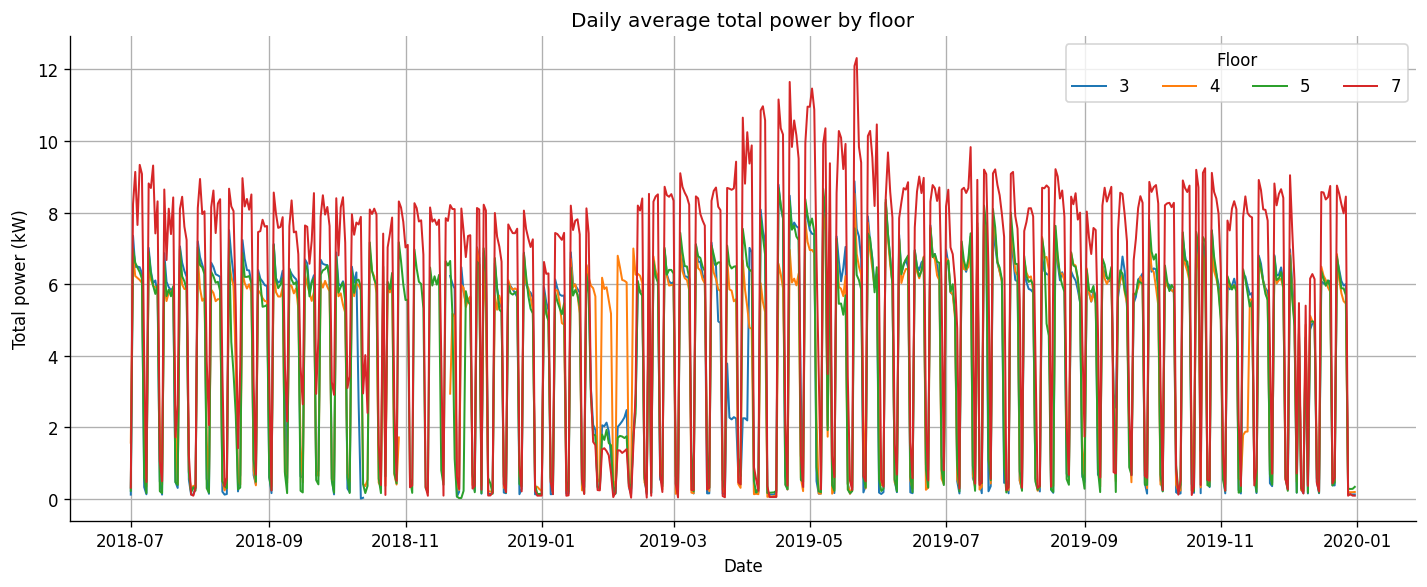

,date,floor,total_power_kw
0,2018-07-01,3,0.113696
1,2018-07-01,4,1.567344
2,2018-07-01,5,0.222153
3,2018-07-01,7,0.308757
4,2018-07-02,3,7.351233


In [42]:
def eda_viz_01_daily_total_power_by_floor(df: pd.DataFrame) -> tuple[plt.Figure, pd.DataFrame, Path]:
    plot_data = (
        df.assign(date=df["timestamp"].dt.date)
        .groupby(["date", "floor"], as_index=False)["total_power_kw"]
        .mean()
        .sort_values(["date", "floor"])
    )

    pivot = plot_data.pivot(index="date", columns="floor", values="total_power_kw")
    fig, ax = plt.subplots(figsize=(12, 5))
    pivot.plot(ax=ax, linewidth=1.2)
    ax.set_title("Daily average total power by floor")
    ax.set_xlabel("Date")
    ax.set_ylabel("Total power (kW)")
    ax.legend(title="Floor", ncol=4)

    file_path = save_and_display_eda_figure(fig, "eda_01_daily_total_power_by_floor.png")
    return fig, plot_data, file_path


fig_daily_power, eda_daily_total_power_by_floor, eda_fig_daily_power_path = eda_viz_01_daily_total_power_by_floor(eda_df)
eda_daily_total_power_by_floor.head()


### Explanation for EDA Figure 01

这张图展示不同楼层的每日平均总用电量。横轴是日期，纵轴是 `total_power_kw` 的日均值，每条线代表一个楼层。观察重点是：某些楼层是否长期高于其他楼层、是否存在突然升高或降低、2018 到 2019 是否有季节性或年度变化。对后续特征工程来说，这张图支持加入 `date`、`month`、`season`、`floor` 以及按楼层计算的 lag/rolling 特征。

## 40. EDA Visualization 02: hourly total power pattern by floor

What this does: plots average `total_power_kw` by hour of day for each floor. This shows daily operating patterns.

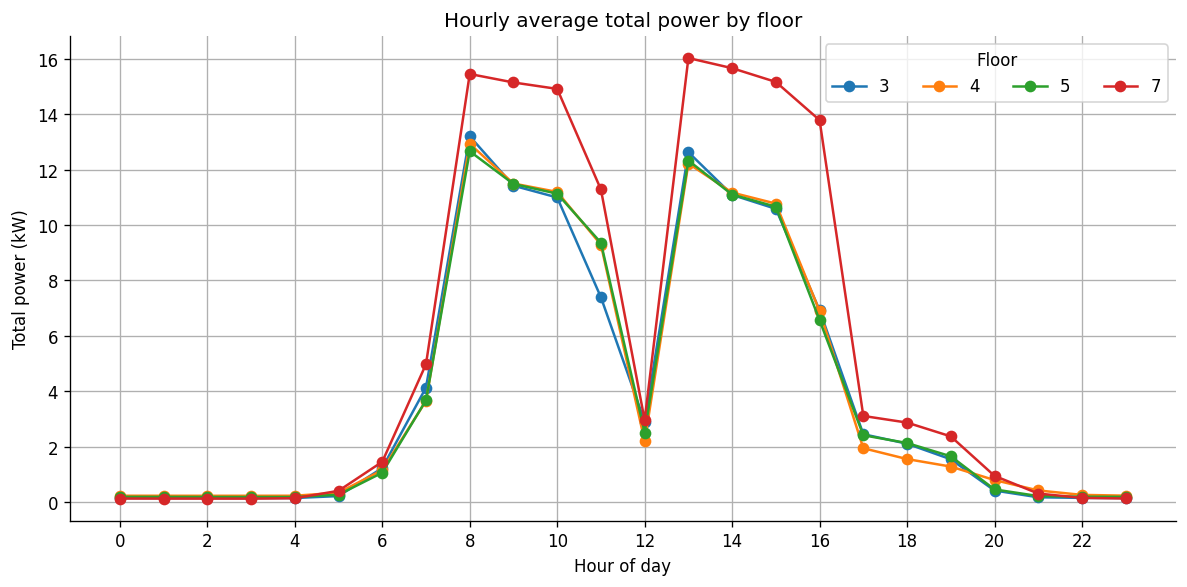

,hour,floor,total_power_kw
0,0,3,0.141641
1,0,4,0.222925
2,0,5,0.182735
3,0,7,0.121514
4,1,3,0.141194


In [43]:
def eda_viz_02_hourly_total_power_by_floor(df: pd.DataFrame) -> tuple[plt.Figure, pd.DataFrame, Path]:
    plot_data = (
        df.assign(hour=df["timestamp"].dt.hour)
        .groupby(["hour", "floor"], as_index=False)["total_power_kw"]
        .mean()
        .sort_values(["hour", "floor"])
    )

    pivot = plot_data.pivot(index="hour", columns="floor", values="total_power_kw")
    fig, ax = plt.subplots(figsize=(10, 5))
    pivot.plot(ax=ax, marker="o", linewidth=1.5)
    ax.set_title("Hourly average total power by floor")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Total power (kW)")
    ax.set_xticks(range(0, 24, 2))
    ax.legend(title="Floor", ncol=4)

    file_path = save_and_display_eda_figure(fig, "eda_02_hourly_total_power_by_floor.png")
    return fig, plot_data, file_path


fig_hourly_power, eda_hourly_total_power_by_floor, eda_fig_hourly_power_path = eda_viz_02_hourly_total_power_by_floor(eda_df)
eda_hourly_total_power_by_floor.head()


### Explanation for EDA Figure 02

这张图展示一天 24 小时内不同楼层的平均用电模式。横轴是小时，纵轴是小时平均 `total_power_kw`。如果白天明显高于夜间，说明用电和建筑使用时间、人员活动或设备运行时间有关。对后续建模来说，应该加入 `hour`、`is_business_hour`、`hour_sin`、`hour_cos` 等时间周期特征。

## 41. EDA Visualization 03: monthly total power trend by floor

What this does: plots monthly average `total_power_kw` for each floor. This helps identify broader seasonal or year-to-year changes.

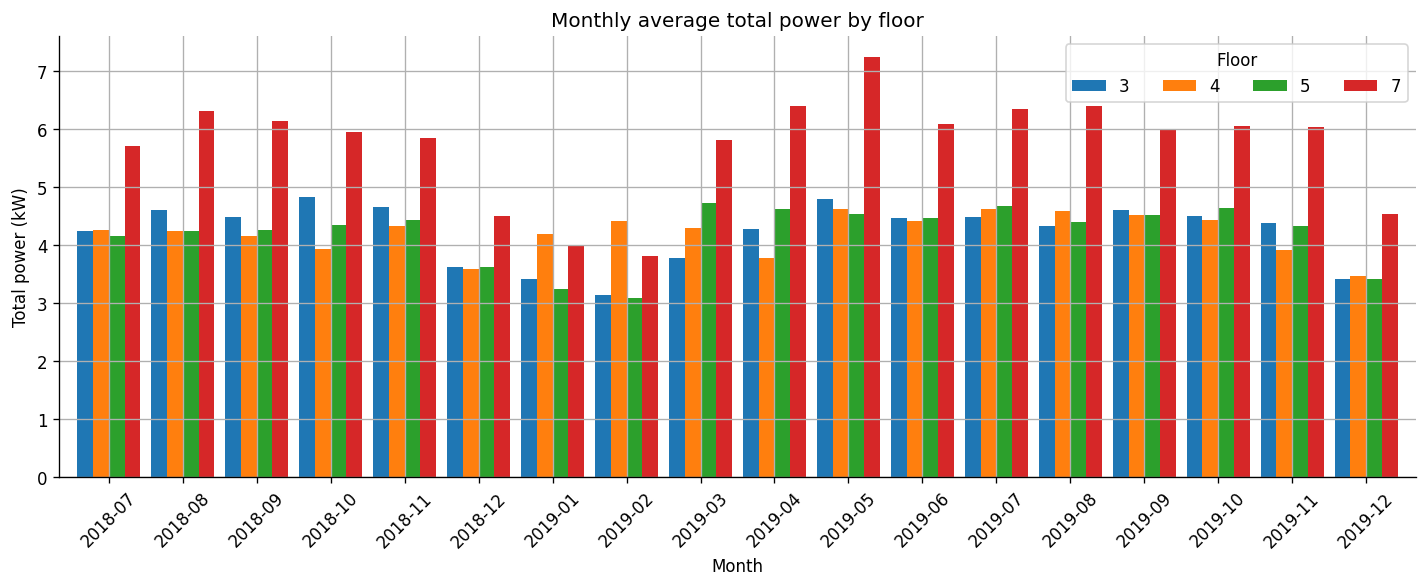

,month,floor,total_power_kw
0,2018-07,3,4.234521
1,2018-07,4,4.259087
2,2018-07,5,4.156363
3,2018-07,7,5.710704
4,2018-08,3,4.597887


In [44]:
def eda_viz_03_monthly_total_power_by_floor(df: pd.DataFrame) -> tuple[plt.Figure, pd.DataFrame, Path]:
    plot_data = (
        df.assign(month=df["timestamp"].dt.to_period("M").astype(str))
        .groupby(["month", "floor"], as_index=False)["total_power_kw"]
        .mean()
        .sort_values(["month", "floor"])
    )

    pivot = plot_data.pivot(index="month", columns="floor", values="total_power_kw")
    fig, ax = plt.subplots(figsize=(12, 5))
    pivot.plot(kind="bar", ax=ax, width=0.85)
    ax.set_title("Monthly average total power by floor")
    ax.set_xlabel("Month")
    ax.set_ylabel("Total power (kW)")
    ax.legend(title="Floor", ncol=4)
    ax.tick_params(axis="x", rotation=45)

    file_path = save_and_display_eda_figure(fig, "eda_03_monthly_total_power_by_floor.png")
    return fig, plot_data, file_path


fig_monthly_power, eda_monthly_total_power_by_floor, eda_fig_monthly_power_path = eda_viz_03_monthly_total_power_by_floor(eda_df)
eda_monthly_total_power_by_floor.head()


### Explanation for EDA Figure 03

这张图比较不同月份和楼层的平均总用电量。它可以帮助判断数据是否存在季节变化、年度差异或某些月份的异常用电。若月度差异明显，后续特征工程应加入 `month`、`year`、`season`，并考虑按月份或季节分别建模或加入交互特征。

## 42. EDA Visualization 04: total power distribution

What this does: plots the distribution of `total_power_kw`. This shows skewness, common usage ranges, and unusual high values.

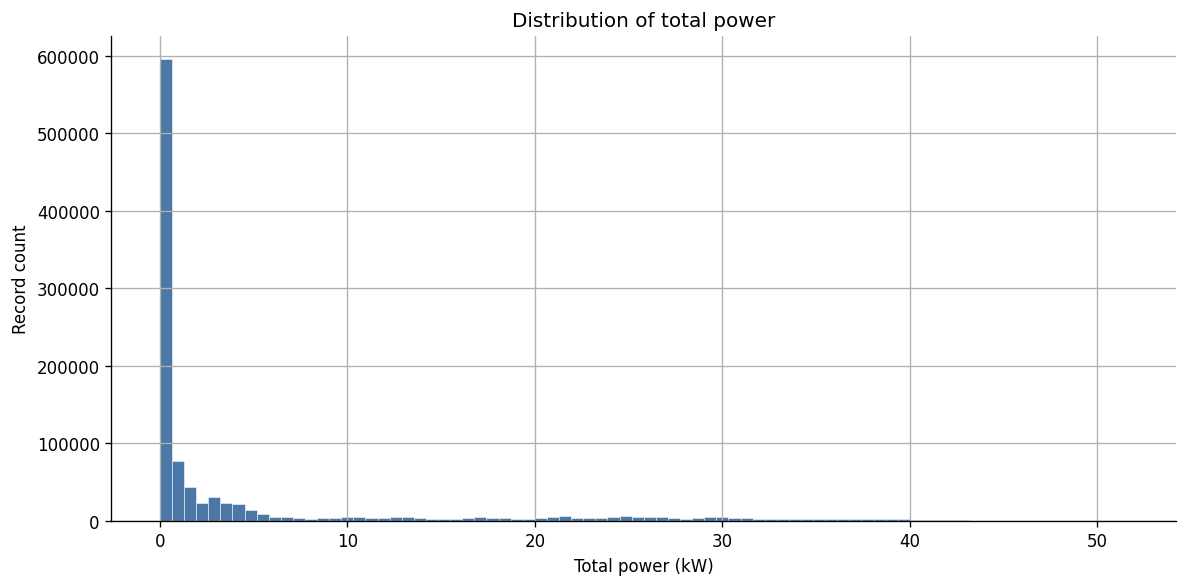

,statistic,value
0,count,1.020715e+06
1,mean,4.592433e+00
2,std,9.144470e+00
3,min,0.000000e+00
4,1%,0.000000e+00
5,5%,1.000000e-02
6,25%,7.800000e-02
7,50%,3.913333e-01
8,75%,3.108000e+00
9,95%,2.821600e+01


In [45]:
def eda_viz_04_total_power_distribution(df: pd.DataFrame) -> tuple[plt.Figure, pd.DataFrame, Path]:
    values = df["total_power_kw"].dropna()
    plot_data = values.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).reset_index()
    plot_data.columns = ["statistic", "value"]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(values, bins=80, color="#4c78a8", edgecolor="white", linewidth=0.3)
    ax.set_title("Distribution of total power")
    ax.set_xlabel("Total power (kW)")
    ax.set_ylabel("Record count")

    file_path = save_and_display_eda_figure(fig, "eda_04_total_power_distribution.png")
    return fig, plot_data, file_path


fig_power_distribution, eda_total_power_distribution_stats, eda_fig_power_distribution_path = eda_viz_04_total_power_distribution(eda_df)
eda_total_power_distribution_stats


### Explanation for EDA Figure 04

这张直方图展示 `total_power_kw` 的整体分布。它可以看出大部分用电值集中在哪个范围，以及是否存在长尾或极端高值。如果分布明显右偏，说明少量高峰用电记录可能会强烈影响模型。后续可以考虑异常值标记、分位数特征，或对目标变量进行 log transformation。

## 43. EDA Visualization 05: total power boxplot by floor

What this does: compares the spread of `total_power_kw` across floors. A sample is used for plotting so the figure stays readable and fast.

/var/folders/p4/f4s_7smj75v4r3f2mdqbl2j40000gn/T/ipykernel_49559/2705175545.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_data, labels=floors, showfliers=False)


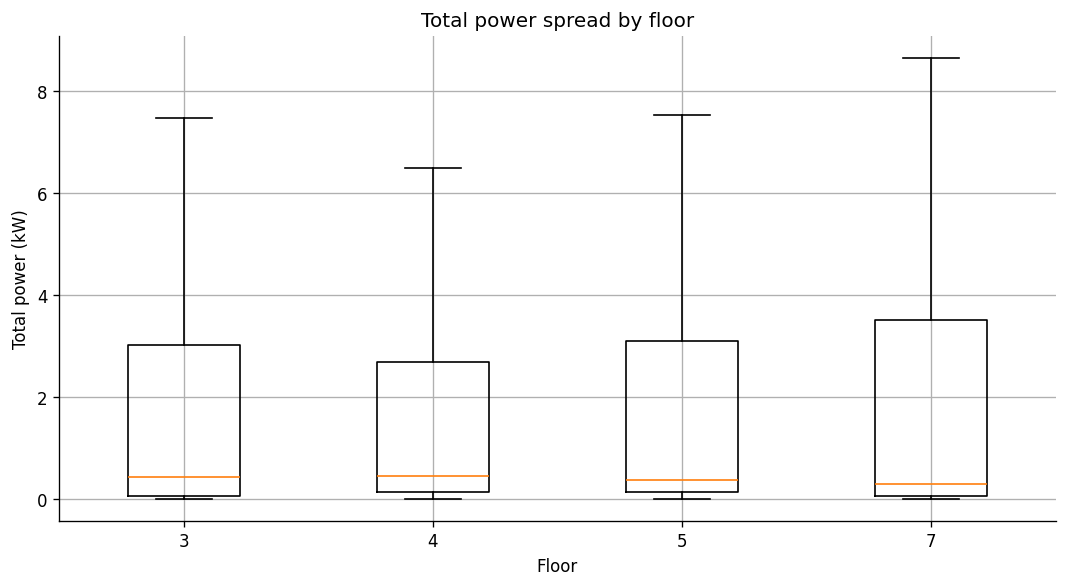

,floor,count,mean,median,min,max
0,3,243802,4.1806,0.4260,0.0,51.6093
1,4,252293,4.2003,0.4467,0.0,50.7650
2,5,261321,4.2036,0.3600,0.0,45.0467
3,7,263299,5.7354,0.2853,0.0,42.8887


In [46]:
def eda_viz_05_total_power_boxplot_by_floor(df: pd.DataFrame, sample_size: int = 100_000) -> tuple[plt.Figure, pd.DataFrame, Path]:
    plot_df = df[["floor", "total_power_kw"]].dropna()
    if len(plot_df) > sample_size:
        plot_df = plot_df.sample(sample_size, random_state=42)

    floors = sorted(plot_df["floor"].unique())
    box_data = [plot_df.loc[plot_df["floor"] == floor, "total_power_kw"] for floor in floors]
    summary = (
        df.groupby("floor", as_index=False)["total_power_kw"]
        .agg(count="count", mean="mean", median="median", min="min", max="max")
        .round(4)
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.boxplot(box_data, labels=floors, showfliers=False)
    ax.set_title("Total power spread by floor")
    ax.set_xlabel("Floor")
    ax.set_ylabel("Total power (kW)")

    file_path = save_and_display_eda_figure(fig, "eda_05_total_power_boxplot_by_floor.png")
    return fig, summary, file_path


fig_power_boxplot, eda_total_power_boxplot_summary, eda_fig_power_boxplot_path = eda_viz_05_total_power_boxplot_by_floor(eda_df)
eda_total_power_boxplot_summary


### Explanation for EDA Figure 05

这张箱线图比较不同楼层 `total_power_kw` 的分布范围。箱体表示主要数据范围，中位线表示典型用电水平。这里隐藏了离群点，使楼层之间的主体差异更容易比较。如果某些楼层的中位数或波动范围明显更高，后续建模时 `floor` 应作为重要类别特征，并且 rolling features 应按楼层分别计算。

## 44. EDA Visualization 06: average total power heatmap by floor and zone

What this does: creates a heatmap of average `total_power_kw` by `floor` and `zone`. This identifies higher-use building areas.

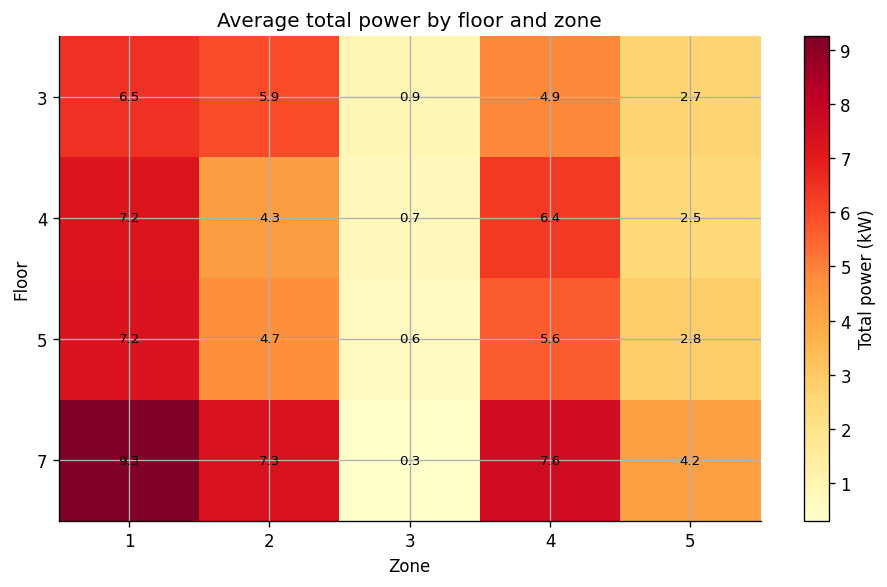

,floor,zone,total_power_kw
0,3,1,6.5012
1,3,2,5.9433
2,3,3,0.8950
3,3,4,4.8818
4,3,5,2.6793
5,4,1,7.2160
6,4,2,4.2705
7,4,3,0.7035
8,4,4,6.3532
9,4,5,2.4575


In [47]:
def eda_viz_06_floor_zone_total_power_heatmap(df: pd.DataFrame) -> tuple[plt.Figure, pd.DataFrame, Path]:
    plot_data = (
        df.groupby(["floor", "zone"], as_index=False)["total_power_kw"]
        .mean()
        .round(4)
        .sort_values(["floor", "zone"])
    )
    pivot = plot_data.pivot(index="floor", columns="zone", values="total_power_kw")

    fig, ax = plt.subplots(figsize=(8, 5))
    image = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd")
    ax.set_title("Average total power by floor and zone")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Floor")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)

    for row_idx in range(pivot.shape[0]):
        for col_idx in range(pivot.shape[1]):
            value = pivot.iloc[row_idx, col_idx]
            ax.text(col_idx, row_idx, f"{value:.1f}", ha="center", va="center", color="black", fontsize=8)

    fig.colorbar(image, ax=ax, label="Total power (kW)")
    file_path = save_and_display_eda_figure(fig, "eda_06_floor_zone_total_power_heatmap.png")
    return fig, plot_data, file_path


fig_floor_zone_heatmap, eda_floor_zone_total_power_heatmap_data, eda_fig_floor_zone_heatmap_path = eda_viz_06_floor_zone_total_power_heatmap(eda_df)
eda_floor_zone_total_power_heatmap_data


### Explanation for EDA Figure 06

这张热力图展示每个 `floor-zone` 组合的平均总用电量。颜色越深表示平均用电越高。它可以快速找出高能耗区域，以及某些 zone 是否在多个楼层中都偏高。对后续特征工程来说，应保留 `floor`、`zone`，并考虑加入 `floor_zone_id` 或按 `floor-zone` 分组计算 lag 和 rolling 特征。

## 45. EDA Visualization 07: missing value percentage by measurement

What this does: plots missing-value percentage for each main measurement column. This makes missingness easier to compare visually.

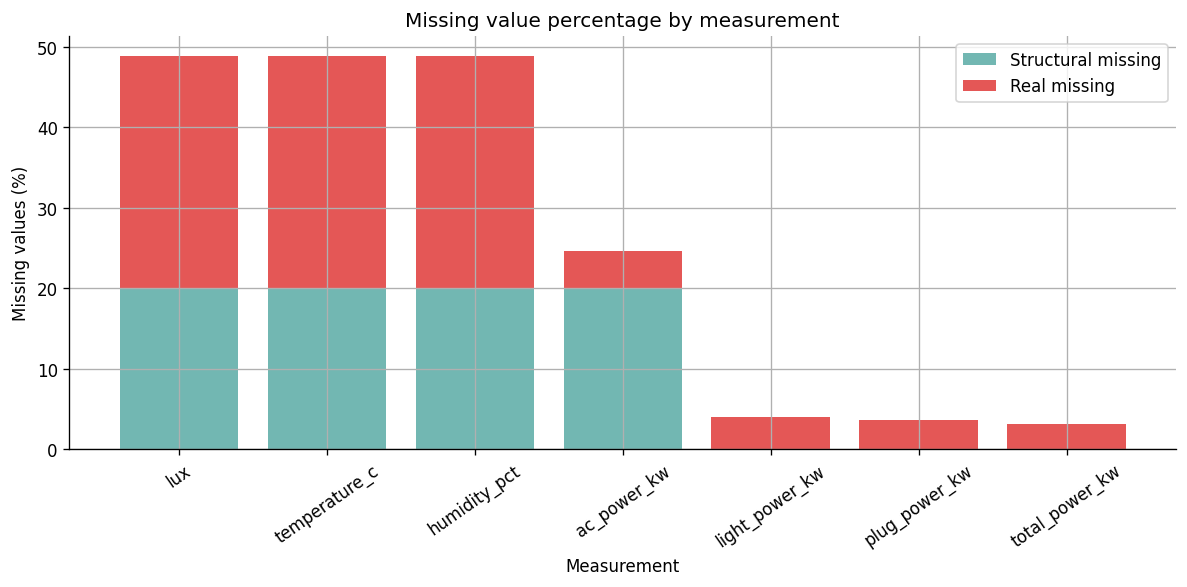

,column_name,total_missing_pct,total_missing_count,structural_missing_pct,real_missing_pct,structural_missing_count,real_missing_count
6,lux,48.9093,515543,20.0,28.9093,210816,304727
4,temperature_c,48.9089,515539,20.0,28.9089,210816,304723
5,humidity_pct,48.9089,515539,20.0,28.9089,210816,304723
0,ac_power_kw,24.5933,259233,20.0,4.5933,210816,48417
1,light_power_kw,3.9794,41946,0.0,3.9794,0,41946
2,plug_power_kw,3.6442,38413,0.0,3.6442,0,38413
3,total_power_kw,3.1653,33365,0.0,3.1653,0,33365


In [48]:
def eda_viz_07_missing_percentage_by_measurement(df: pd.DataFrame, measurement_columns: list[str]) -> tuple[plt.Figure, pd.DataFrame, Path]:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    plot_data = pd.DataFrame({
        "column_name": available_measurements,
        "total_missing_pct": [df[col].isna().mean() * 100 for col in available_measurements],
        "total_missing_count": [int(df[col].isna().sum()) for col in available_measurements],
    })

    type_summary = eda_step_06_missing_type_summary(df, {col: MISSING_TYPE_SENSOR_MAP[col] for col in available_measurements})
    plot_data = plot_data.merge(
        type_summary[["measurement_column", "structural_missing_pct", "real_missing_pct", "structural_missing_count", "real_missing_count"]],
        left_on="column_name",
        right_on="measurement_column",
        how="left",
    ).drop(columns=["measurement_column"])
    plot_data = plot_data.sort_values("total_missing_pct", ascending=False)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(plot_data["column_name"], plot_data["structural_missing_pct"], label="Structural missing", color="#72b7b2")
    ax.bar(plot_data["column_name"], plot_data["real_missing_pct"], bottom=plot_data["structural_missing_pct"], label="Real missing", color="#e45756")
    ax.set_title("Missing value percentage by measurement")
    ax.set_xlabel("Measurement")
    ax.set_ylabel("Missing values (%)")
    ax.tick_params(axis="x", rotation=35)
    ax.legend()

    file_path = save_and_display_eda_figure(fig, "eda_07_missing_percentage_by_measurement.png")
    return fig, plot_data.round(4), file_path


fig_missing_pct, eda_missing_percentage_by_measurement, eda_fig_missing_pct_path = eda_viz_07_missing_percentage_by_measurement(eda_df, MEASUREMENT_COLUMNS)
eda_missing_percentage_by_measurement


### Explanation for EDA Figure 07

这张柱状图展示主要测量字段的缺失比例，并进一步把缺失拆成结构性缺失和真实缺失。结构性缺失来自该 `floor-zone-measurement` 本来没有对应传感器，不能直接当作异常。真实缺失表示传感器存在但某个时间点没有记录到值，更适合作为 data quality anomaly。后续生成 anomaly label 时，应保留结构性缺失信息，但只把真实缺失纳入异常事件候选。


## 46. EDA Visualization 08: measurement correlation heatmap

What this does: plots correlations among the main measurement columns. This helps identify related variables before feature engineering and model building.

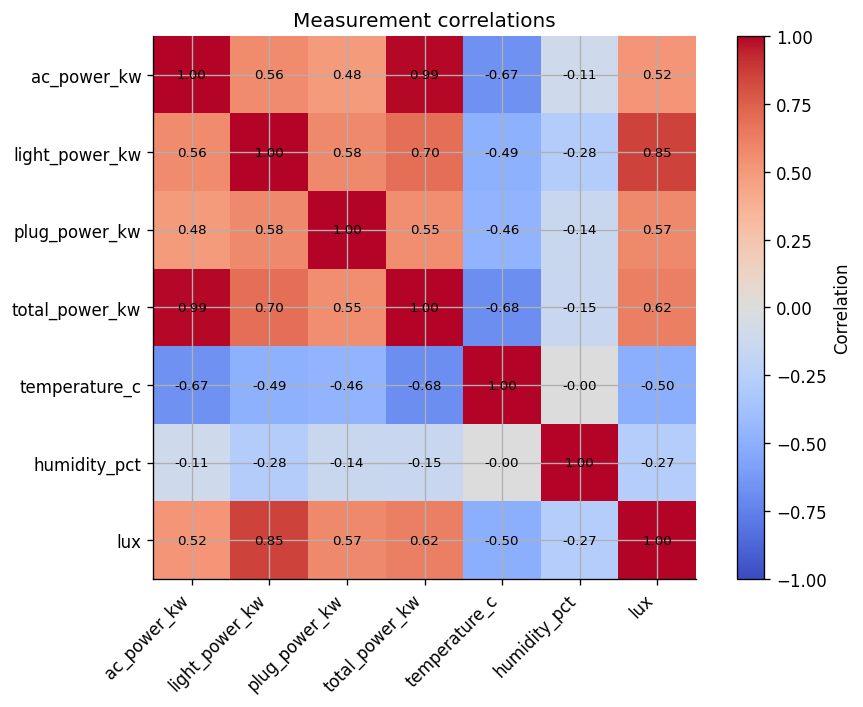

,measurement,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux
0,ac_power_kw,1.0000,0.5627,0.4846,0.9863,-0.6692,-0.1065,0.5231
1,light_power_kw,0.5627,1.0000,0.5781,0.6951,-0.4857,-0.2806,0.8536
2,plug_power_kw,0.4846,0.5781,1.0000,0.5495,-0.4638,-0.1372,0.5721
3,total_power_kw,0.9863,0.6951,0.5495,1.0000,-0.6824,-0.1468,0.6221
4,temperature_c,-0.6692,-0.4857,-0.4638,-0.6824,1.0000,-0.0041,-0.5025
5,humidity_pct,-0.1065,-0.2806,-0.1372,-0.1468,-0.0041,1.0000,-0.2722
6,lux,0.5231,0.8536,0.5721,0.6221,-0.5025,-0.2722,1.0000


In [49]:
def eda_viz_08_measurement_correlation_heatmap(df: pd.DataFrame, measurement_columns: list[str]) -> tuple[plt.Figure, pd.DataFrame, Path]:
    available_measurements = [col for col in measurement_columns if col in df.columns]
    corr = df[available_measurements].corr().round(4)

    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_title("Measurement correlations")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)

    for row_idx in range(corr.shape[0]):
        for col_idx in range(corr.shape[1]):
            ax.text(col_idx, row_idx, f"{corr.iloc[row_idx, col_idx]:.2f}", ha="center", va="center", fontsize=8)

    fig.colorbar(image, ax=ax, label="Correlation")
    file_path = save_and_display_eda_figure(fig, "eda_08_measurement_correlation_heatmap.png")
    return fig, corr.reset_index().rename(columns={"index": "measurement"}), file_path


fig_corr_heatmap, eda_correlation_heatmap_data, eda_fig_corr_heatmap_path = eda_viz_08_measurement_correlation_heatmap(eda_df, MEASUREMENT_COLUMNS)
eda_correlation_heatmap_data


### Explanation for EDA Figure 08

这张相关性热力图展示主要测量变量之间的线性关系。相关系数接近 1 表示强正相关，接近 -1 表示强负相关，接近 0 表示线性关系较弱。如果 `temperature_c`、`humidity_pct` 或 `lux` 与 `total_power_kw` 有明显相关性，它们可以作为预测用电的重要输入特征。若两个变量高度相关，后续建模时需要注意特征冗余。

## 47. EDA Visualization 09: temperature versus total power

What this does: plots a sampled scatter chart of `temperature_c` against `total_power_kw`. This checks whether power demand changes with temperature.

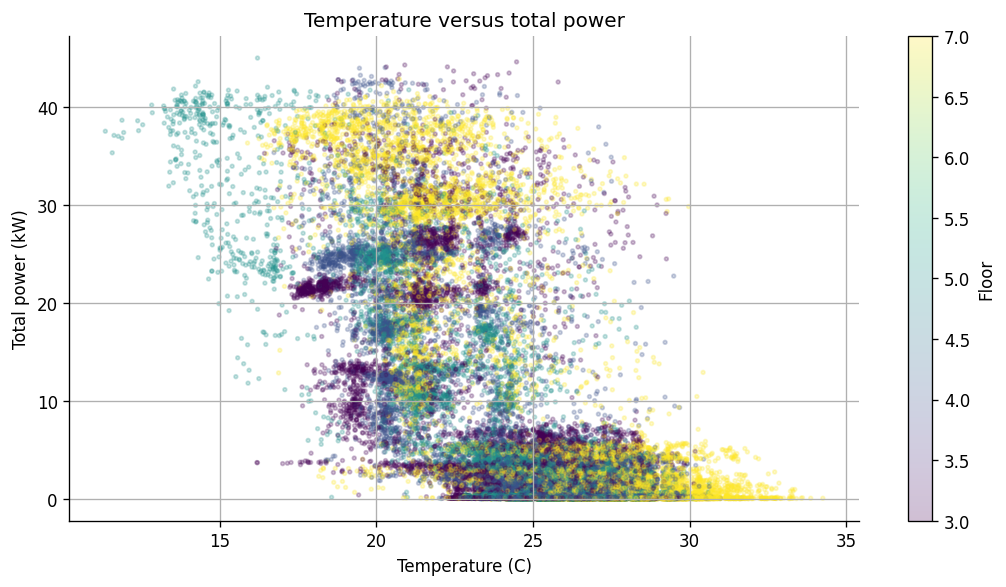

,measurement,temperature_c,total_power_kw
0,temperature_c,1.0000,-0.6824
1,total_power_kw,-0.6824,1.0000


In [50]:
def eda_viz_09_temperature_vs_total_power(df: pd.DataFrame, sample_size: int = 50_000) -> tuple[plt.Figure, pd.DataFrame, Path]:
    plot_df = df[["temperature_c", "total_power_kw", "floor"]].dropna()
    if len(plot_df) > sample_size:
        plot_df = plot_df.sample(sample_size, random_state=42)

    summary = (
        df[["temperature_c", "total_power_kw"]]
        .dropna()
        .corr()
        .round(4)
        .reset_index()
        .rename(columns={"index": "measurement"})
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    scatter = ax.scatter(plot_df["temperature_c"], plot_df["total_power_kw"], c=plot_df["floor"], s=5, alpha=0.25, cmap="viridis")
    ax.set_title("Temperature versus total power")
    ax.set_xlabel("Temperature (C)")
    ax.set_ylabel("Total power (kW)")
    fig.colorbar(scatter, ax=ax, label="Floor")

    file_path = save_and_display_eda_figure(fig, "eda_09_temperature_vs_total_power.png")
    return fig, summary, file_path


fig_temp_power, eda_temperature_total_power_correlation, eda_fig_temp_power_path = eda_viz_09_temperature_vs_total_power(eda_df)
eda_temperature_total_power_correlation


### Explanation for EDA Figure 09

这张散点图检查温度和总用电量之间的关系。每个点代表一个时间、楼层和区域记录，颜色代表楼层。观察重点是：温度升高时用电是否也升高，不同楼层是否呈现不同关系。如果温度和用电存在非线性关系，后续可以加入温度分箱、温度平方项、冷/热阈值特征，或按楼层建立交互特征。

## 48. EDA Visualization 10: highest total power records

What this does: plots the top `total_power_kw` records and labels each bar by floor and zone. This makes peak-load cases easier to inspect.

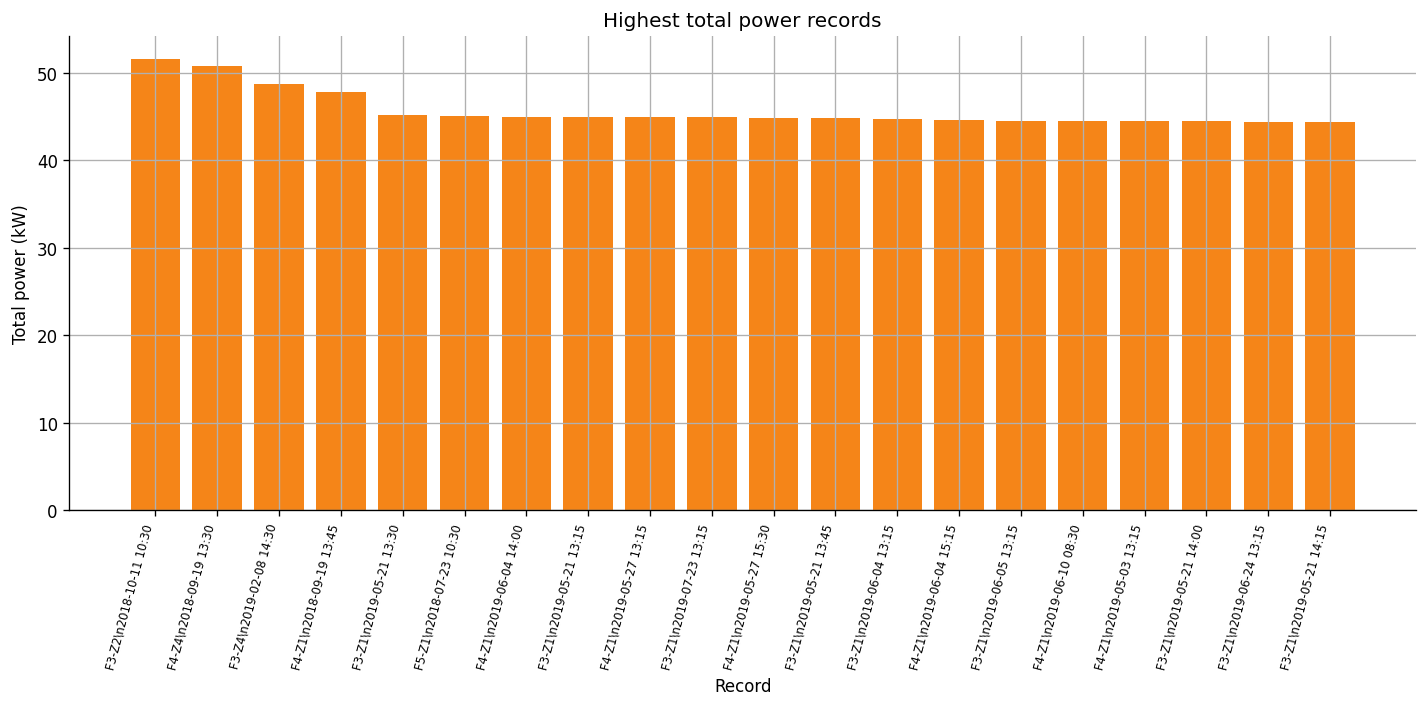

,timestamp,floor,zone,total_power_kw
0,2018-10-11 10:30:00,3,2,51.609333
1,2018-09-19 13:30:00,4,4,50.765000
2,2019-02-08 14:30:00,3,4,48.756000
3,2018-09-19 13:45:00,4,1,47.755000
4,2019-05-21 13:30:00,3,1,45.141333
5,2018-07-23 10:30:00,5,1,45.046667
6,2019-06-04 14:00:00,4,1,44.942000
7,2019-05-21 13:15:00,3,1,44.906000
8,2019-05-27 13:15:00,4,1,44.886667
9,2019-07-23 13:15:00,3,1,44.878667


In [51]:
def eda_viz_10_highest_total_power_records(df: pd.DataFrame, top_n: int = 20) -> tuple[plt.Figure, pd.DataFrame, Path]:
    plot_data = (
        df[["timestamp", "floor", "zone", "total_power_kw"]]
        .dropna(subset=["total_power_kw"])
        .sort_values("total_power_kw", ascending=False)
        .head(top_n)
        .copy()
    )
    plot_data["label"] = plot_data.apply(lambda row: f"F{int(row['floor'])}-Z{int(row['zone'])}\\n{row['timestamp']:%Y-%m-%d %H:%M}", axis=1)

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(range(len(plot_data)), plot_data["total_power_kw"], color="#f58518")
    ax.set_title("Highest total power records")
    ax.set_xlabel("Record")
    ax.set_ylabel("Total power (kW)")
    ax.set_xticks(range(len(plot_data)))
    ax.set_xticklabels(plot_data["label"], rotation=75, ha="right", fontsize=7)

    file_path = save_and_display_eda_figure(fig, "eda_10_highest_total_power_records.png")
    return fig, plot_data.drop(columns=["label"]).reset_index(drop=True), file_path


fig_peak_power, eda_highest_total_power_plot_data, eda_fig_peak_power_path = eda_viz_10_highest_total_power_records(eda_df, top_n=20)
eda_highest_total_power_plot_data


### Explanation for EDA Figure 10

这张图列出 `total_power_kw` 最高的若干条记录，并标注对应楼层、区域和时间。它用于检查峰值用电是否集中在某些楼层、区域或时间段。若峰值记录集中在特定位置或时段，后续应加入 peak-hour 标记、floor-zone 分组特征，并在模型评估时特别关注高峰用电预测效果。

## 49. EDA Visualization 11: save figure index

What this does: saves a figure index table with each EDA image file path. This makes it easier to locate figures for the report.

In [52]:
def eda_viz_11_save_figure_index() -> pd.DataFrame:
    figure_records = [
        {"figure_id": "eda_01", "description": "Daily average total power by floor", "file_path": str(eda_fig_daily_power_path)},
        {"figure_id": "eda_02", "description": "Hourly average total power by floor", "file_path": str(eda_fig_hourly_power_path)},
        {"figure_id": "eda_03", "description": "Monthly average total power by floor", "file_path": str(eda_fig_monthly_power_path)},
        {"figure_id": "eda_04", "description": "Distribution of total power", "file_path": str(eda_fig_power_distribution_path)},
        {"figure_id": "eda_05", "description": "Total power spread by floor", "file_path": str(eda_fig_power_boxplot_path)},
        {"figure_id": "eda_06", "description": "Average total power by floor and zone", "file_path": str(eda_fig_floor_zone_heatmap_path)},
        {"figure_id": "eda_07", "description": "Missing value percentage by measurement", "file_path": str(eda_fig_missing_pct_path)},
        {"figure_id": "eda_08", "description": "Measurement correlations", "file_path": str(eda_fig_corr_heatmap_path)},
        {"figure_id": "eda_09", "description": "Temperature versus total power", "file_path": str(eda_fig_temp_power_path)},
        {"figure_id": "eda_10", "description": "Highest total power records", "file_path": str(eda_fig_peak_power_path)},
    ]
    figure_index = pd.DataFrame(figure_records)
    output_path = OUTPUT_DIR / f"eda_figure_index_{EDA_OUTPUT_PREFIX}.csv"
    figure_index.to_csv(output_path, index=False)
    figure_index["index_file_path"] = str(output_path)
    return figure_index


eda_figure_index = eda_viz_11_save_figure_index()
display(eda_figure_index)


,figure_id,description,file_path,index_file_path
0,eda_01,Daily average total power by floor,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
1,eda_02,Hourly average total power by floor,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
2,eda_03,Monthly average total power by floor,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
3,eda_04,Distribution of total power,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
4,eda_05,Total power spread by floor,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
5,eda_06,Average total power by floor and zone,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
6,eda_07,Missing value percentage by measurement,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
7,eda_08,Measurement correlations,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
8,eda_09,Temperature versus total power,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
9,eda_10,Highest total power records,/Users/yonglijiang/Documents/Adelaide Universi...,/Users/yonglijiang/Documents/Adelaide Universi...
